<table style="width:100%; font-size:11pt; border-collapse:collapse">
    <tr>
        <td colspan="2"
            style="border: 1px #0098cd solid;
                   background-color:#E6F4F9;
                   color:#0098CD;
                   text-align:center;
                   font-weight:bold;
                   padding:8px;">
            Universidad de Oriente
        </td>
    </tr>
    <tr>
        <td style="border: 1px #0098cd solid;
                   background-color:#E6F4F9;
                   color:#0098CD;
                   width:50%;
                   text-align:center;
                   padding:6px;">
            Ciencia de Datos
        </td>
        <td style="border: 1px #0098cd solid;
                   background-color:#E6F4F9;
                   color:#0098CD;
                   width:50%;
                   text-align:center;
                   padding:6px;">
            Investigación - Regresión Poisson Regularizada
        </td>
    </tr>
</table>

# Modelado Predictivo de Incidentes de Ciberseguridad mediante Regresión Poisson Regularizada

El presente trabajo de investigación aborda el análisis y modelado de datos de conteo en el ámbito de la ciberseguridad corporativa. Se analiza el número mensual de incidentes de seguridad (`MonthlySecurityIncidents`) experimentados por diversas organizaciones en función de variables de infraestructura tecnológica, prácticas operativas, políticas de gobernanza y sectores organizacionales.

### Objetivos del Estudio:
1. **Carga y Exploración Inicial:** Inspeccionar dimensiones, tipología de datos, valores faltantes y métricas estadísticas descriptivas.
2. **Análisis Exploratorio de Datos (EDA) Exhaustivo:**
   - Histogramas y distribuciones de todas las variables.
   - Diagramas de caja (box plots) para la identificación de atípicos.
   - Mapa de calor de valores nulos.
   - Matrices de correlación lineal y no paramétrica (Pearson, Spearman y Kendall).
   - Diagramas de violín y de enjambre (swarm/strip plots) de factores clave versus la variable de respuesta.
   - Detección formal de valores atípicos mediante los métodos del Rango Intercuartílico (IQR) y Z-Score ($|Z| > 3$).
3. **Preprocesamiento:** Imputación rigurosa de valores faltantes, codificación One-Hot para variables categóricas, estandarización de predictoras continuas (`StandardScaler`) y partición entrenamiento/prueba (80/20).
4. **Modelado con 4 Variantes de Regresión Poisson:**
   - Poisson sin regularización (MLE tradicional).
   - Poisson con regularización Ridge ($L_2$).
   - Poisson con regularización Lasso ($L_1$).
   - Poisson con regularización Elastic Net ($L_1 + L_2$).
   - Diagnóstico gráfico individual para cada variante: dispersión de residuos y valores reales vs. predichos.
5. **Evaluación Comparativa:** Cuadro comparativo de desempeño empleando métricas fundamentales: MAE (Error Absoluto Medio), Poisson Deviance (Devianza Media de Poisson), y $R^2$ / $D^2$.
6. **Significancia Estadística de Variables:** Inferencia a través de Modelos Lineales Generalizados (`statsmodels.GLM`) con distribución de Poisson y función de enlace logarítmica para obtener estimadores, errores estándar, estadísticos $z$ y valores $p$.
7. **Optimización de Hiperparámetros:** Búsqueda en cuadrícula (`GridSearchCV`) con validación cruzada ($K$-Fold) para optimizar el coeficiente de penalización $\alpha$ y el balance $l_1$-ratio.


In [1]:
# Importación de librerías esenciales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy import stats

# Modelado y evaluación
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance, r2_score, d2_tweedie_score
from sklearn.base import BaseEstimator, RegressorMixin

# Inferencia estadística
import statsmodels.api as sm

# Configuración visual y de advertencias
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Semilla de reproducibilidad
SEED = 2026
np.random.seed(SEED)

## 1. Carga y Exploración Inicial del Conjunto de Datos

Se procede a cargar el archivo CSV `poisson_regularization_cyber_incidents.csv` empleando la librería `pandas`. Se examinan las dimensiones del conjunto, las primeras observaciones, los tipos de datos de cada columna, la presencia preliminar de valores nulos y las estadísticas de resumen.


In [3]:
# Carga del conjunto de datos
ruta_dataset = '../unidad 1/datasets/poisson_regularization_cyber_incidents.csv'
df = pd.read_csv(ruta_dataset)

df.head(10)


,EmployeeCount,ManagedEndpoints,ExternalTrafficGB,UnpatchedSystems,MeanPatchDelayDays,PhishingEmailsReported,SecurityTrainingHours,FailedLoginAttempts,PrivilegedAccounts,ThreatAlerts,BackupCoveragePct,OrganizationSector,CloudAdoptionLevel,SecurityPolicy,MonthlySecurityIncidents
0,339,393,273.0,22,14.0,21.0,4.4,72.0,24,84.0,80.0,Education,OnPremises,Standard,38
1,253,204,206.0,14,11.0,19.0,4.7,45.0,18,19.0,98.0,Education,OnPremises,Standard,1
2,307,284,264.0,18,18.0,18.0,3.3,72.0,20,80.0,97.0,FinancialServices,OnPremises,Standard,2
3,235,197,107.0,31,36.0,25.0,1.5,67.0,18,52.0,70.0,Retail,CloudFirst,Basic,2
4,259,243,200.0,31,25.0,19.0,1.5,69.0,20,46.0,77.0,Logistics,Hybrid,Basic,0
5,277,261,138.0,6,11.0,24.0,8.3,72.0,19,56.0,100.0,Retail,Hybrid,Advanced,2
6,171,184,175.0,6,10.0,23.0,11.3,100.0,17,44.0,100.0,Healthcare,OnPremises,Advanced,2
7,116,115,101.0,15,22.0,0.0,3.1,32.0,2,17.0,82.0,Logistics,OnPremises,Basic,1
8,160,184,289.0,0,9.0,23.0,5.2,20.0,8,54.0,86.0,Retail,Hybrid,Advanced,0
9,255,298,166.0,19,10.0,19.0,5.1,101.0,14,67.0,87.0,Healthcare,OnPremises,Standard,4


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1780 entries, 0 to 1779
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmployeeCount             1780 non-null   int64  
 1   ManagedEndpoints          1780 non-null   int64  
 2   ExternalTrafficGB         1726 non-null   float64
 3   UnpatchedSystems          1780 non-null   int64  
 4   MeanPatchDelayDays        1668 non-null   float64
 5   PhishingEmailsReported    1723 non-null   float64
 6   SecurityTrainingHours     1739 non-null   float64
 7   FailedLoginAttempts       1725 non-null   float64
 8   PrivilegedAccounts        1780 non-null   int64  
 9   ThreatAlerts              1660 non-null   float64
 10  BackupCoveragePct         1708 non-null   float64
 11  OrganizationSector        1780 non-null   str    
 12  CloudAdoptionLevel        1714 non-null   str    
 13  SecurityPolicy            1717 non-null   str    
 14  MonthlySecurityInci

In [5]:
# Cuantificación de valores nulos o faltantes por variable
conteo_nulos = df.isnull().sum()
porcentaje_nulos = (conteo_nulos / len(df)) * 100

resumen_nulos = pd.DataFrame({
    'Valores Nulos': conteo_nulos,
    'Porcentaje (%)': porcentaje_nulos.round(2)
})

display(resumen_nulos[resumen_nulos['Valores Nulos'] > 0])


,Valores Nulos,Porcentaje (%)
ExternalTrafficGB,54,3.03
MeanPatchDelayDays,112,6.29
PhishingEmailsReported,57,3.20
SecurityTrainingHours,41,2.30
FailedLoginAttempts,55,3.09
ThreatAlerts,120,6.74
BackupCoveragePct,72,4.04
CloudAdoptionLevel,66,3.71
SecurityPolicy,63,3.54


In [6]:
# Estadísticas descriptivas de las variables cuantitativas
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
EmployeeCount,1780.0,227.40,133.47,62.0,139.0,192.0,271.25,1490.0
ManagedEndpoints,1780.0,233.73,144.18,21.0,139.0,197.0,279.00,1778.0
ExternalTrafficGB,1726.0,202.03,102.53,70.0,135.0,176.0,240.00,1167.0
UnpatchedSystems,1780.0,17.44,14.86,0.0,7.0,14.0,23.00,122.0
MeanPatchDelayDays,1668.0,16.28,8.58,2.0,9.0,16.0,23.00,41.0
PhishingEmailsReported,1723.0,14.84,11.17,0.0,7.0,13.0,21.00,93.0
SecurityTrainingHours,1739.0,4.59,3.07,0.0,2.0,4.1,6.80,14.6
FailedLoginAttempts,1725.0,69.54,40.39,0.0,42.0,64.0,90.00,394.0
PrivilegedAccounts,1780.0,13.86,7.52,1.0,9.0,12.0,17.00,78.0
ThreatAlerts,1660.0,53.74,28.25,0.0,35.0,50.0,67.00,317.0


In [6]:
# Análisis específico de la variable objetivo (MonthlySecurityIncidents)
print("--- Análisis de la Variable Objetivo: MonthlySecurityIncidents ---")
media_y = df['MonthlySecurityIncidents'].mean()
var_y = df['MonthlySecurityIncidents'].var()
zeros_y = (df['MonthlySecurityIncidents'] == 0).sum()
pct_zeros = (zeros_y / len(df)) * 100

print(f"Media muestral (λ): {media_y:.4f}")
print(f"Varianza muestral:   {var_y:.4f}")
print(f"Razón Varianza/Media (Sobredispersión): {var_y / media_y:.4f}")
print(f"Organizaciones con 0 incidentes: {zeros_y} ({pct_zeros:.2f}%)")


--- Análisis de la Variable Objetivo: MonthlySecurityIncidents ---
Media muestral (λ): 2.6955
Varianza muestral:   22.6751
Razón Varianza/Media (Sobredispersión): 8.4122
Organizaciones con 0 incidentes: 462 (25.96%)


## 2. Análisis Exploratorio de Datos (EDA)

En esta sección se aplican los elementos analíticos y visuales mínimos requeridos por el instructivo institucional:
1. **Histogramas:** Evaluación de la forma de las distribuciones cuantitativas y categóricas.
2. **Diagramas de Caja (Box Plots):** Detección visual de valores atípicos y dispersión.
3. **Mapa de Calor de Valores Nulos:** Inspección visual de los patrones de valores faltantes.
4. **Matrices de Correlación $\times 3$:** Evaluación de dependencias lineales y no lineales mediante coeficientes de Pearson, Spearman y Kendall para las variables cuantitativas.
5. **Diagramas de Violín y de Enjambre (Swarm/Strip):** Relación entre factores categóricos y la variable de respuesta.
6. **Detección Formal de Atípicos:** Métodos estadísticos del Rango Intercuartílico (IQR) y desviación Z-score ($|Z| > 3$).


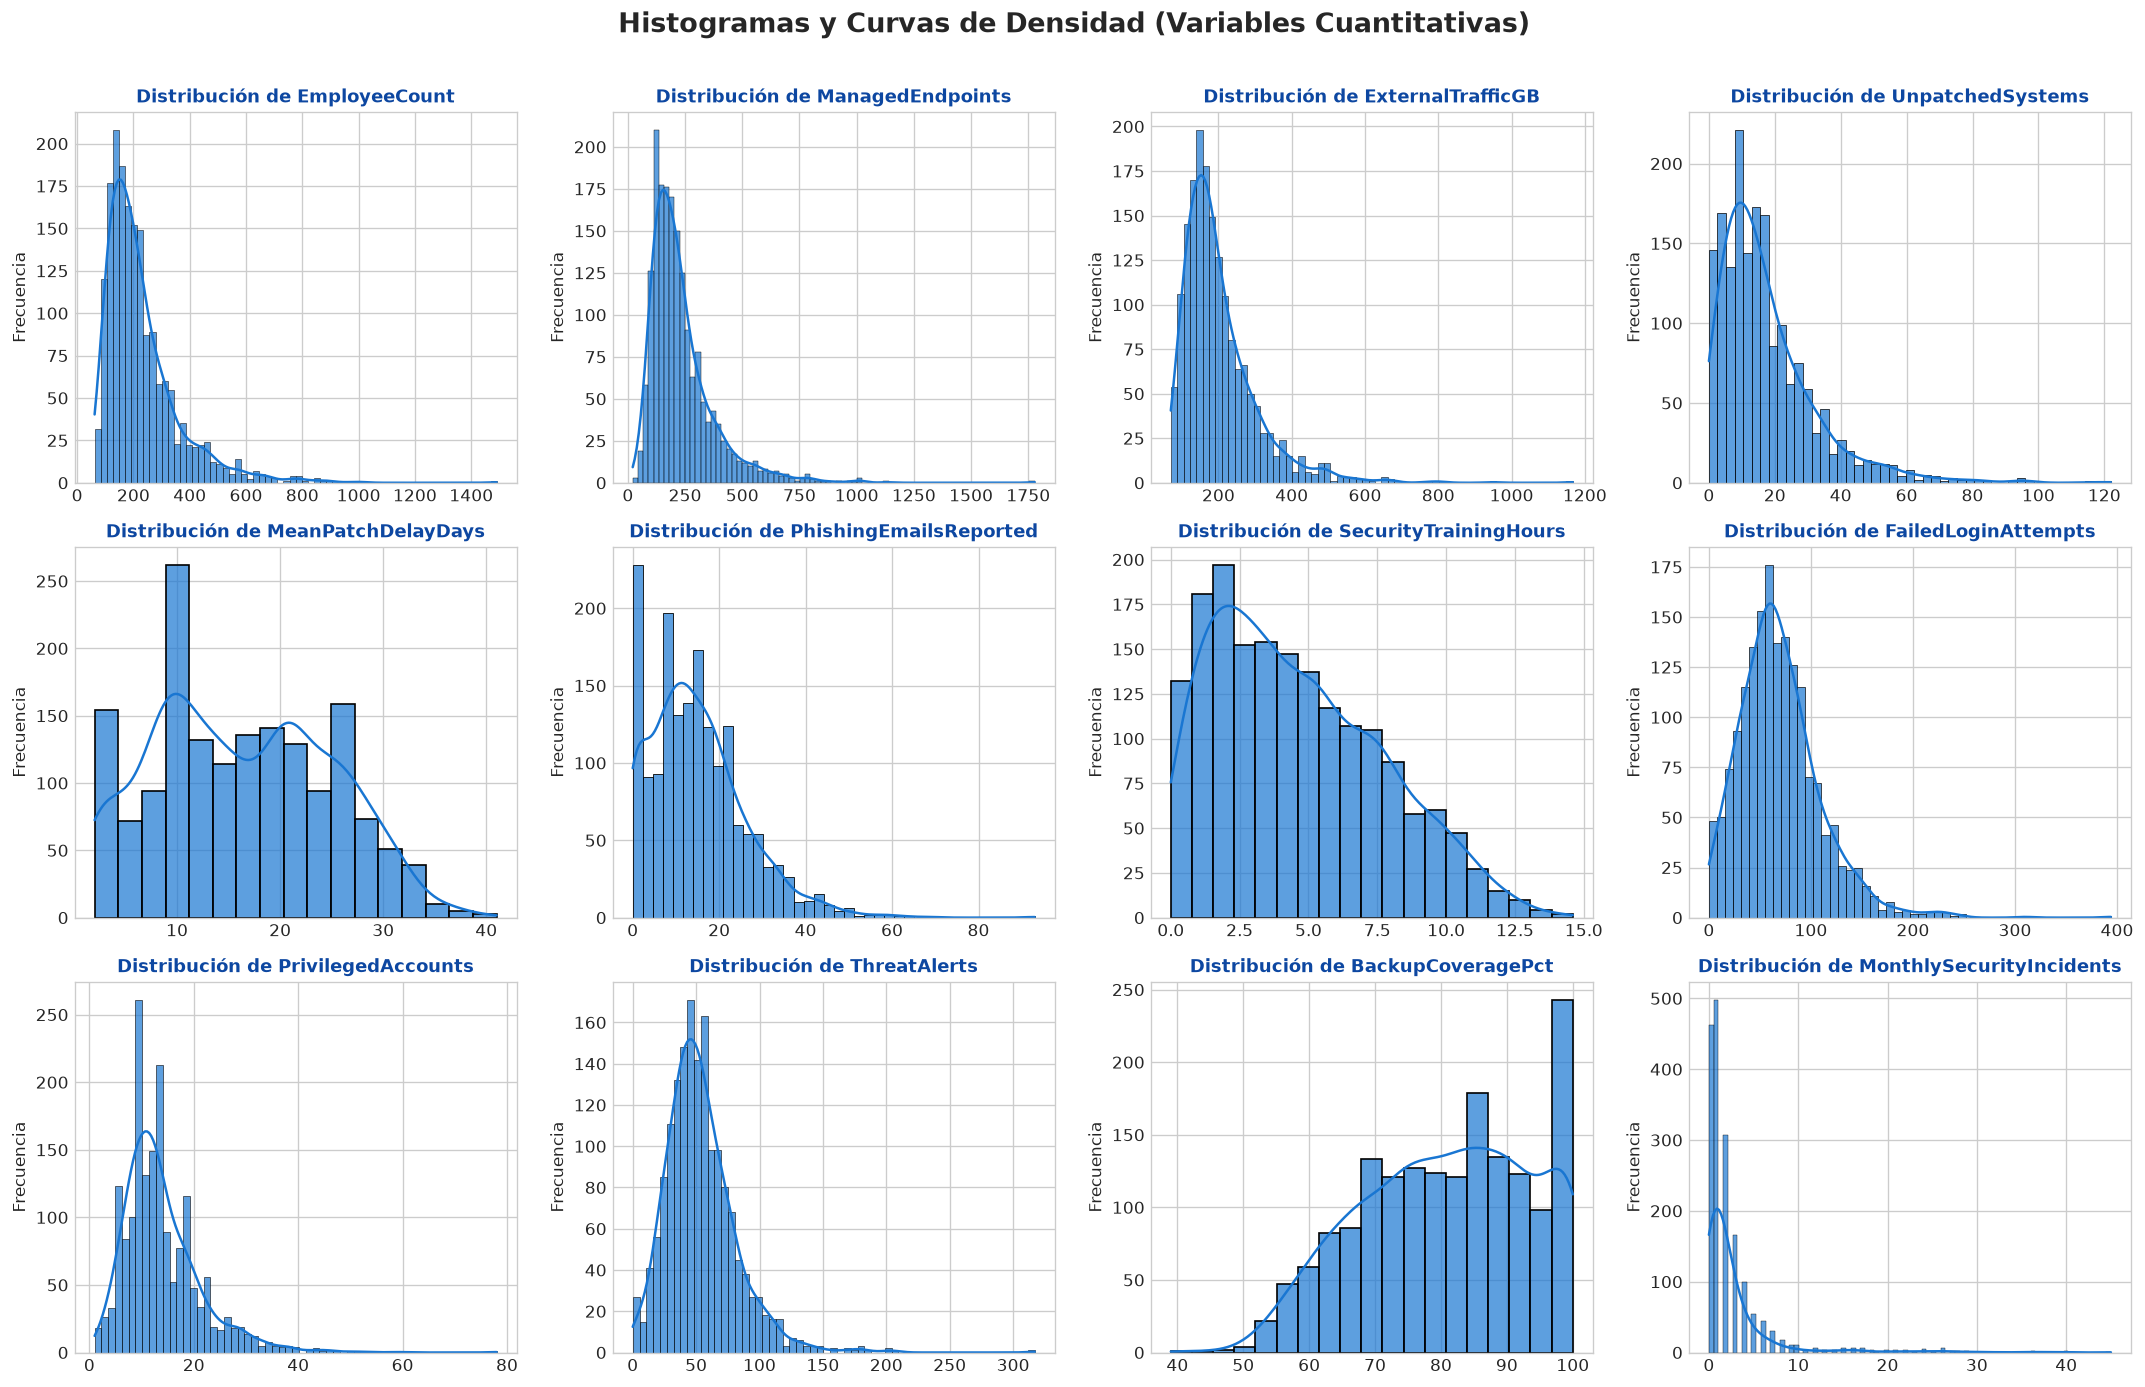

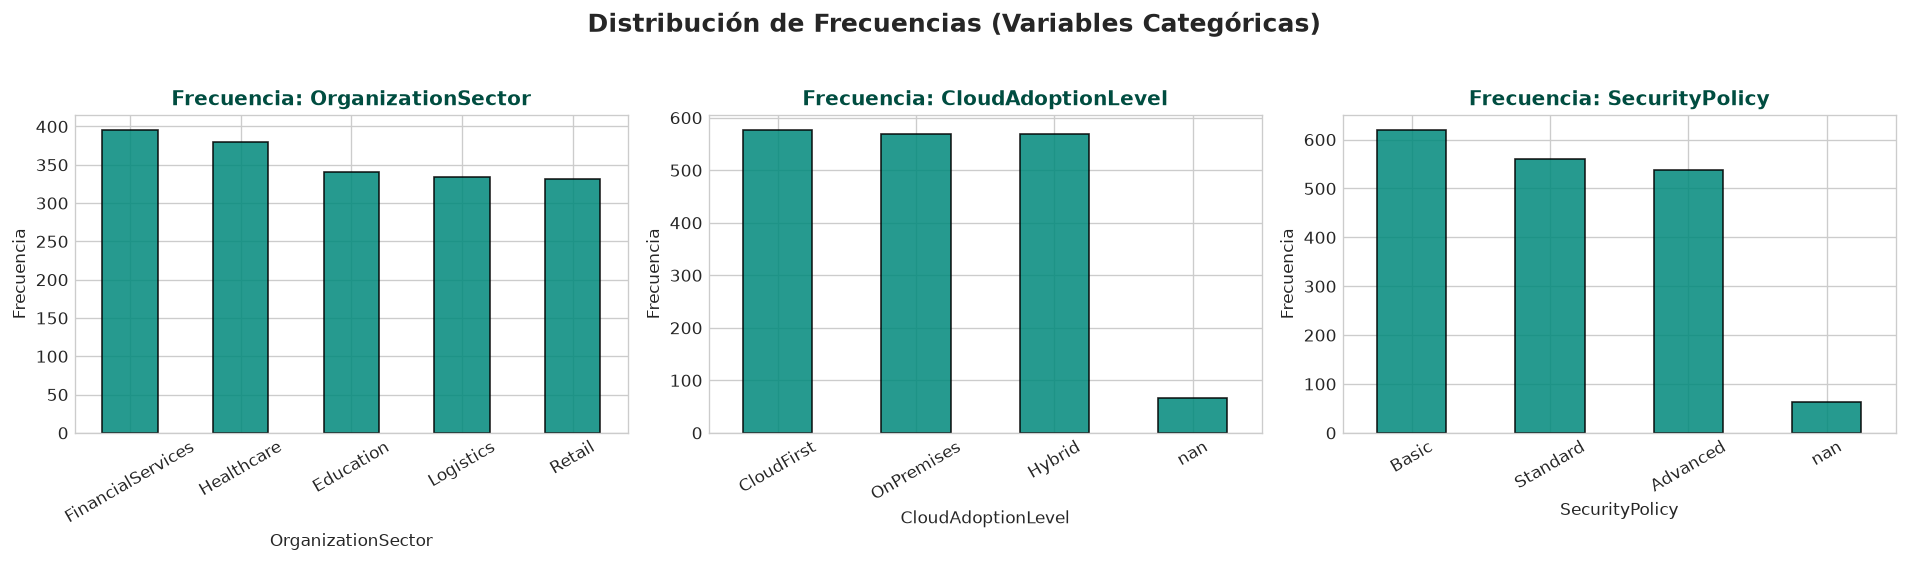

In [7]:
# 1. Histogramas de todas las variables numéricas y diagramas de barras para categóricas
columnas_num = df.select_dtypes(include=[np.number]).columns
columnas_cat = df.select_dtypes(include=['object', 'string', 'str']).columns

# Histogramas de variables numéricas
n_num = len(columnas_num)
filas_num = (n_num + 3) // 4
fig, axes = plt.subplots(filas_num, 4, figsize=(18, filas_num * 3.8), dpi=120)
axes = axes.flatten()

for i, col in enumerate(columnas_num):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color='#1976d2', edgecolor='black', alpha=0.7)
    axes[i].set_title(f"Distribución de {col}", fontsize=11, fontweight='bold', color='#0d47a1')
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frecuencia")

# Ocultar ejes sobrantes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Histogramas y Curvas de Densidad (Variables Cuantitativas)", fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Diagramas de frecuencia para variables cualitativas
fig, axes_cat = plt.subplots(1, len(columnas_cat), figsize=(16, 4.5), dpi=120)
for i, col in enumerate(columnas_cat):
    df[col].value_counts(dropna=False).plot(kind='bar', ax=axes_cat[i], color='#00897b', edgecolor='black', alpha=0.85)
    axes_cat[i].set_title(f"Frecuencia: {col}", fontsize=12, fontweight='bold', color='#004d40')
    axes_cat[i].set_ylabel("Frecuencia")
    axes_cat[i].tick_params(axis='x', rotation=30)

plt.suptitle("Distribución de Frecuencias (Variables Categóricas)", fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


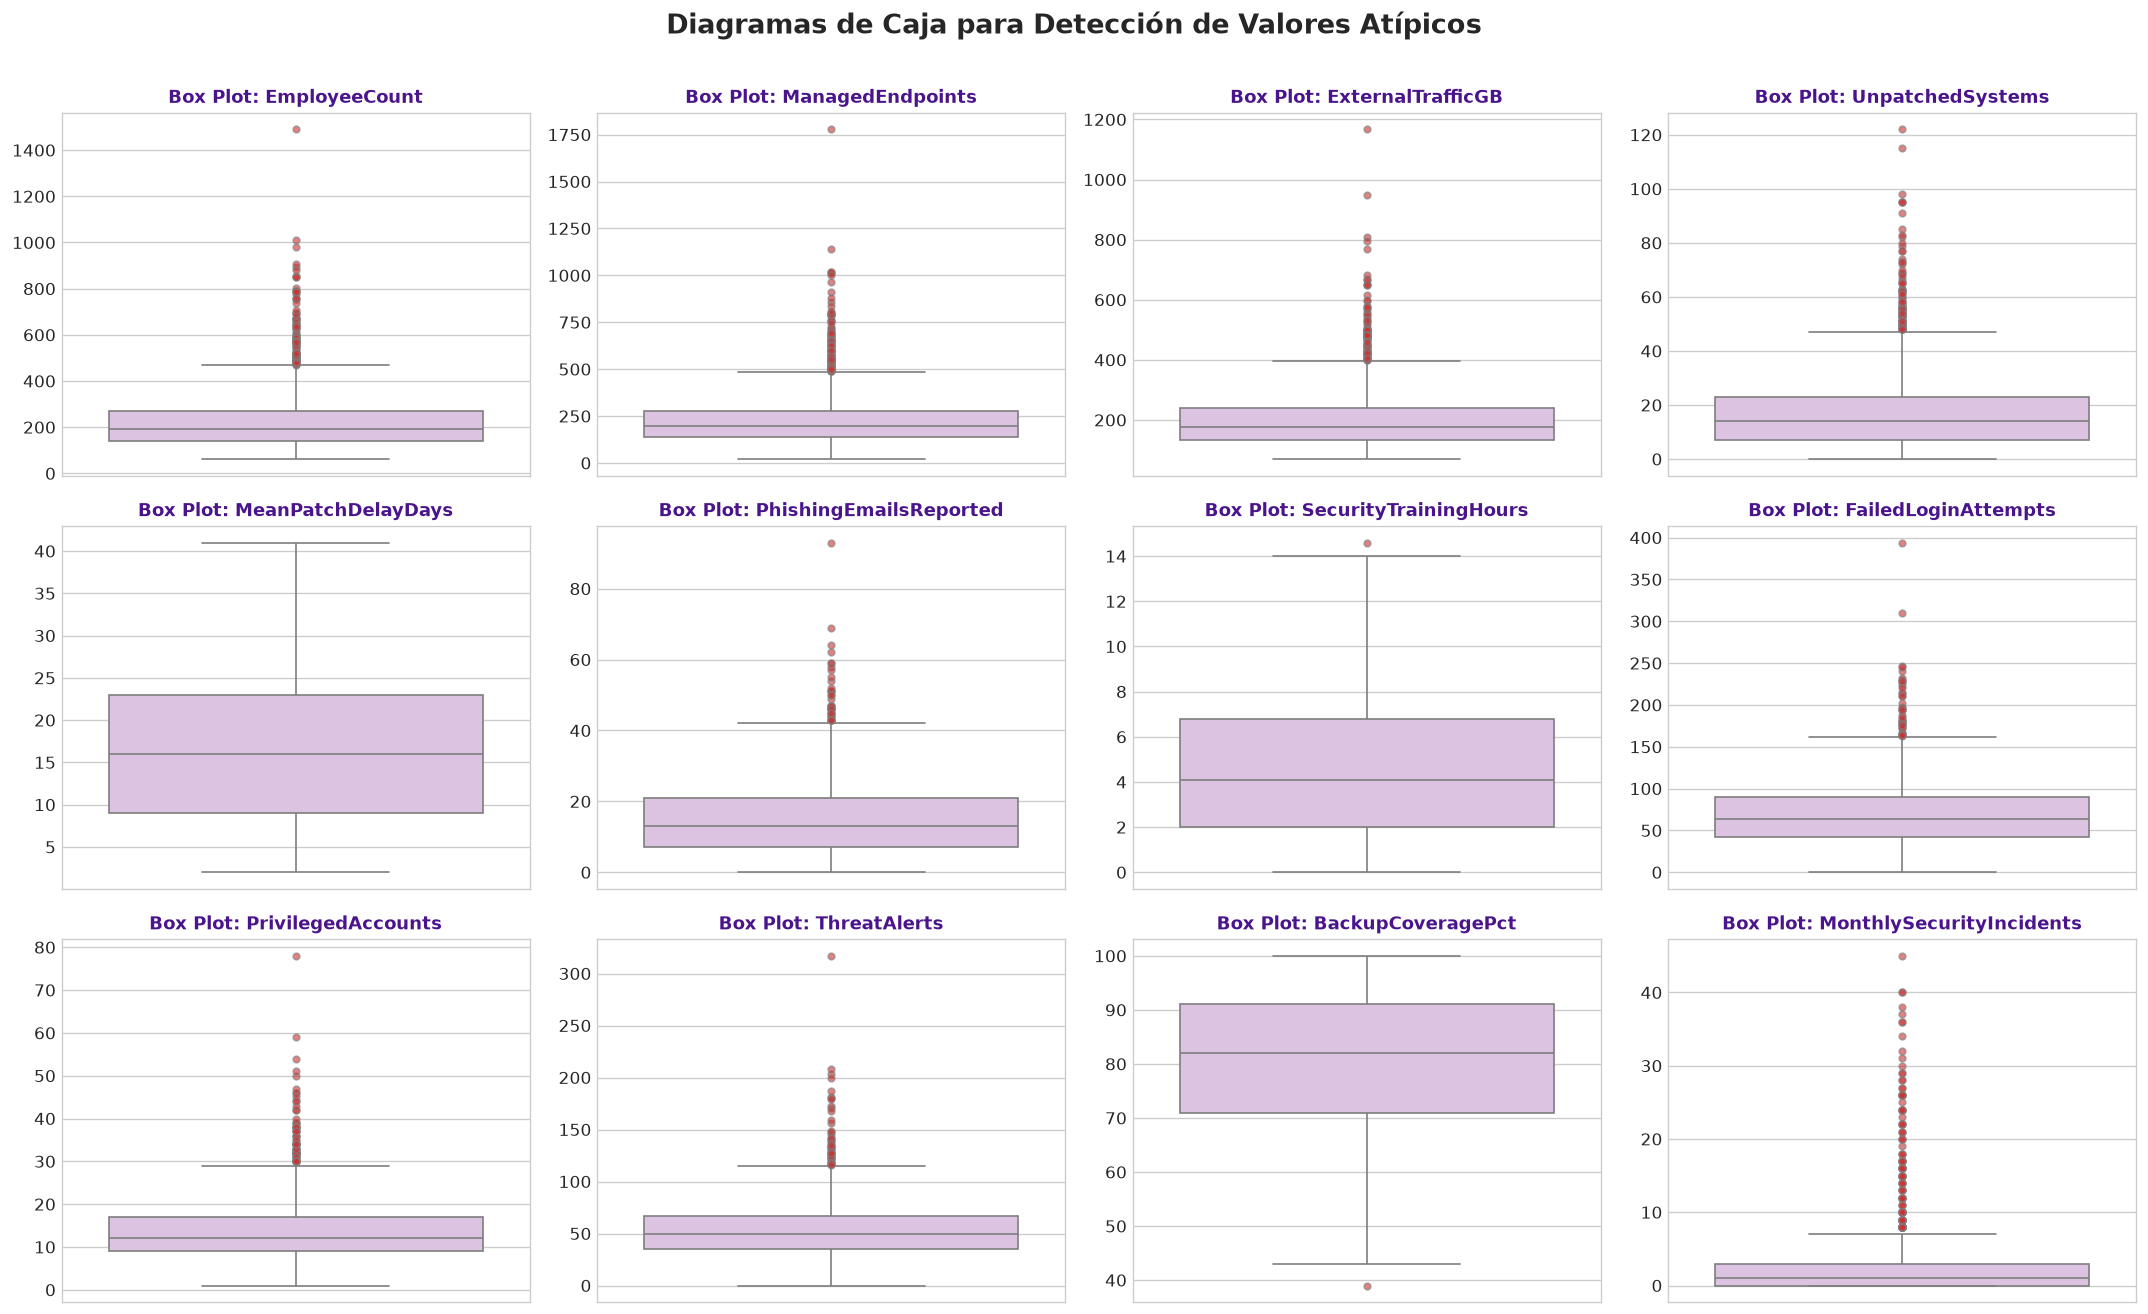

In [8]:
# 2. Diagramas de Caja (Box Plots) para identificar valores atípicos en variables numéricas
fig, axes = plt.subplots(filas_num, 4, figsize=(18, filas_num * 3.6), dpi=120)
axes = axes.flatten()

for i, col in enumerate(columnas_num):
    sns.boxplot(y=df[col].dropna(), ax=axes[i], color='#e1bee7', flierprops=dict(marker='o', markerfacecolor='#d32f2f', markersize=4, alpha=0.6))
    axes[i].set_title(f"Box Plot: {col}", fontsize=11, fontweight='bold', color='#4a148c')
    axes[i].set_ylabel("")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Diagramas de Caja para Detección de Valores Atípicos", fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


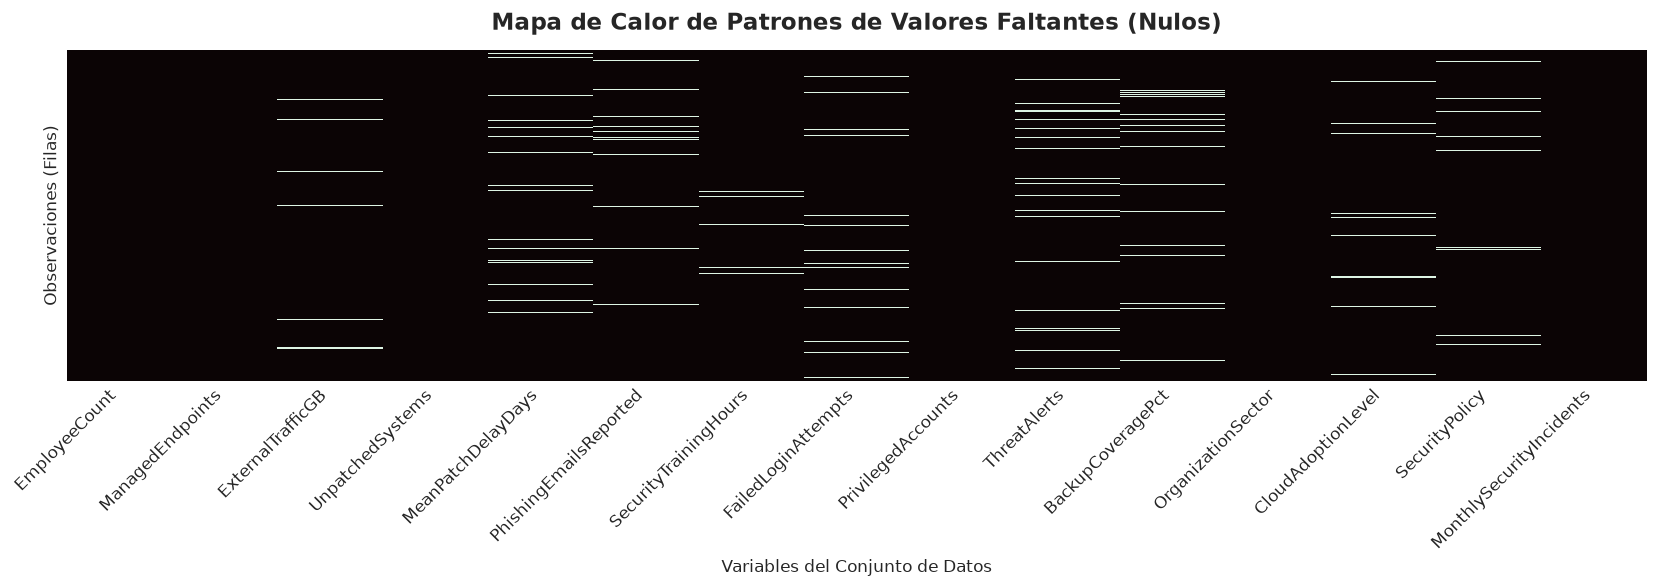

In [9]:
# 3. Mapa de calor de valores nulos (Missing Data Heatmap)
plt.figure(figsize=(14, 5), dpi=120)
sns.heatmap(df.isnull(), cbar=False, cmap='mako', yticklabels=False)
plt.title("Mapa de Calor de Patrones de Valores Faltantes (Nulos)", fontsize=14, fontweight='bold', pad=12)
plt.xlabel("Variables del Conjunto de Datos")
plt.ylabel("Observaciones (Filas)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


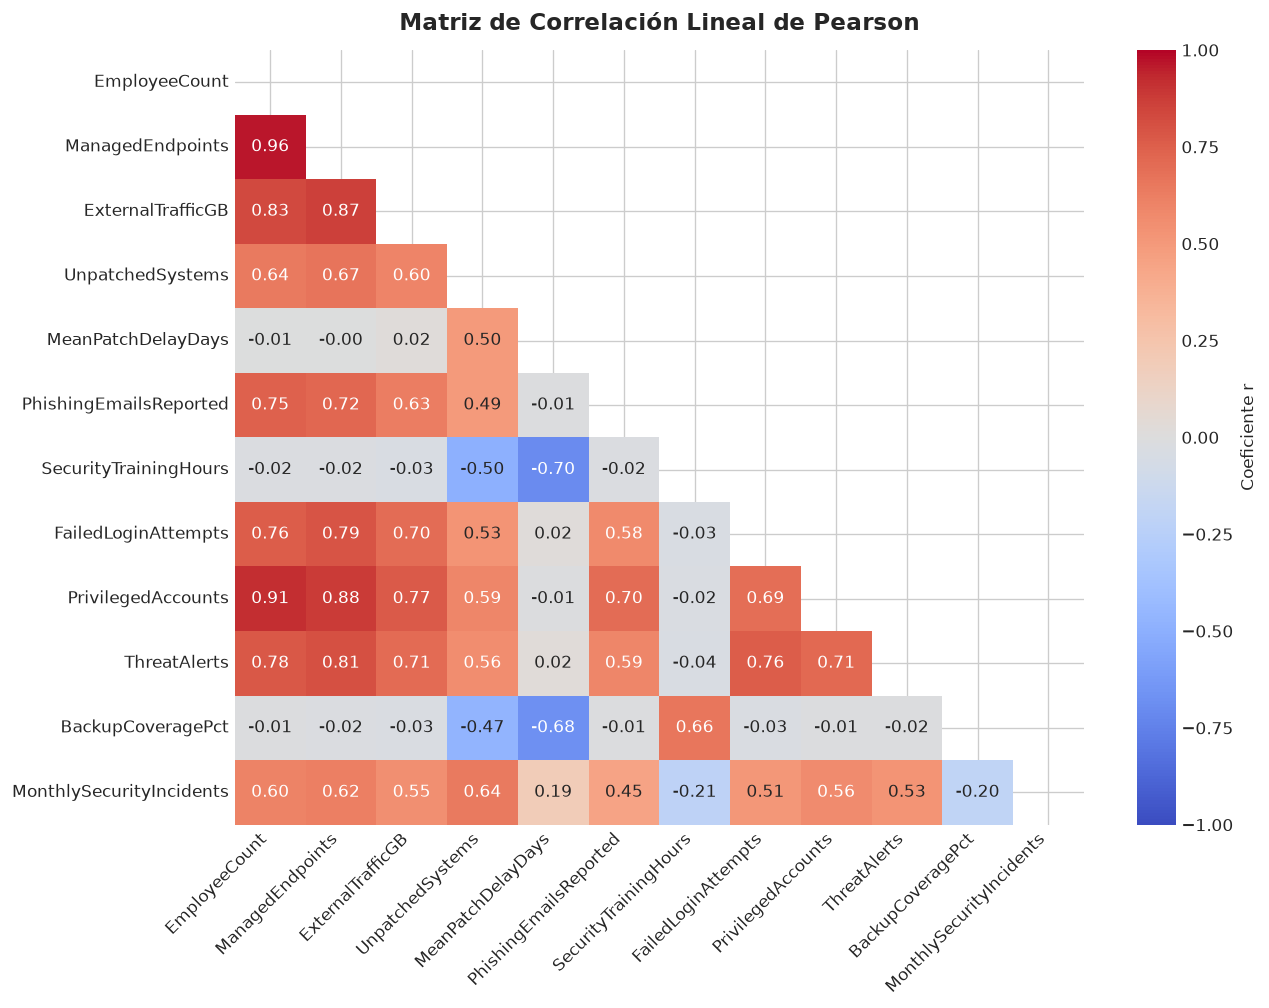

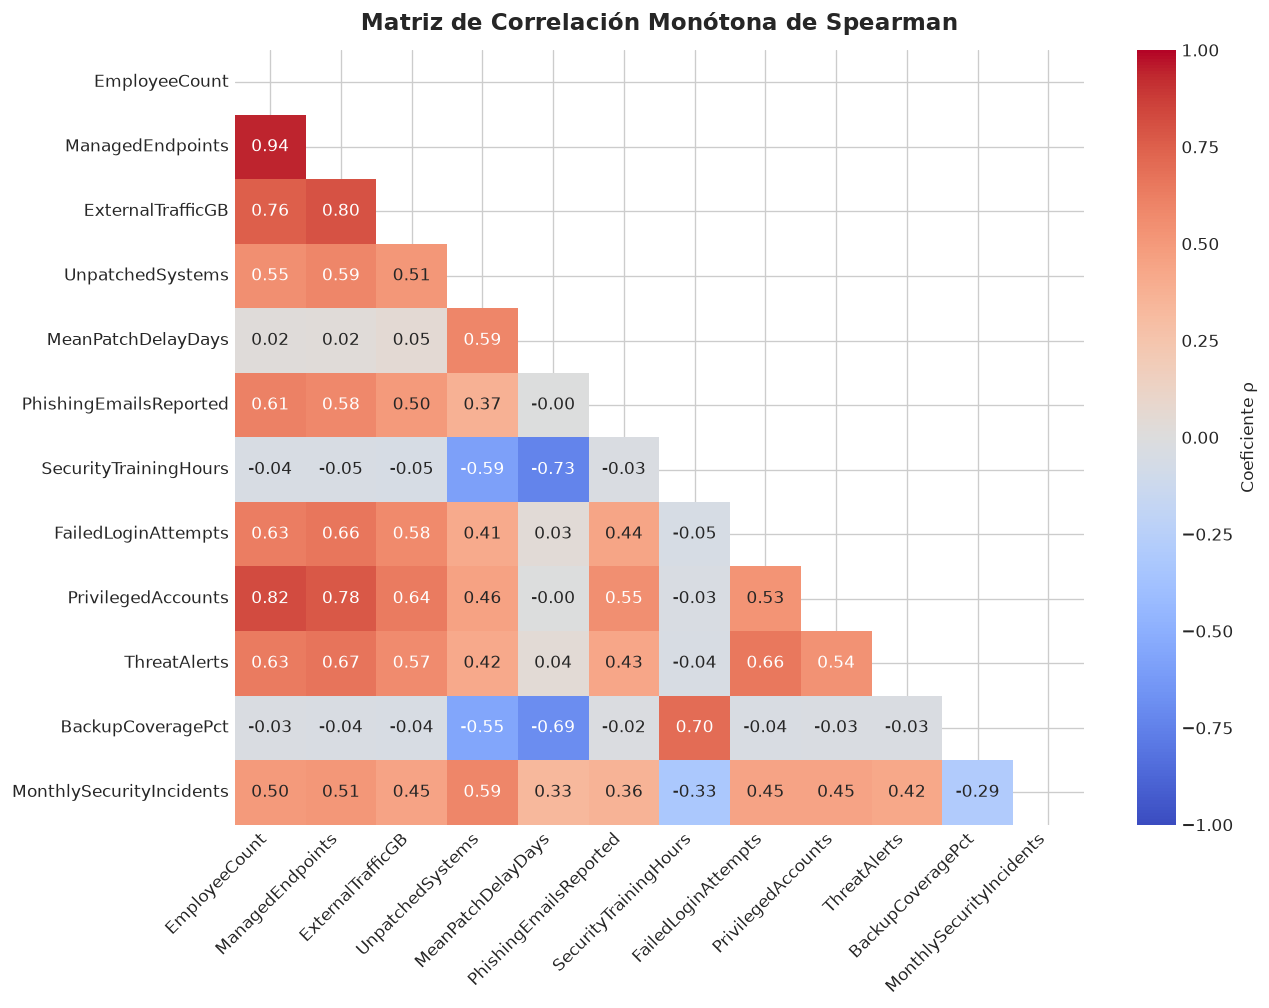

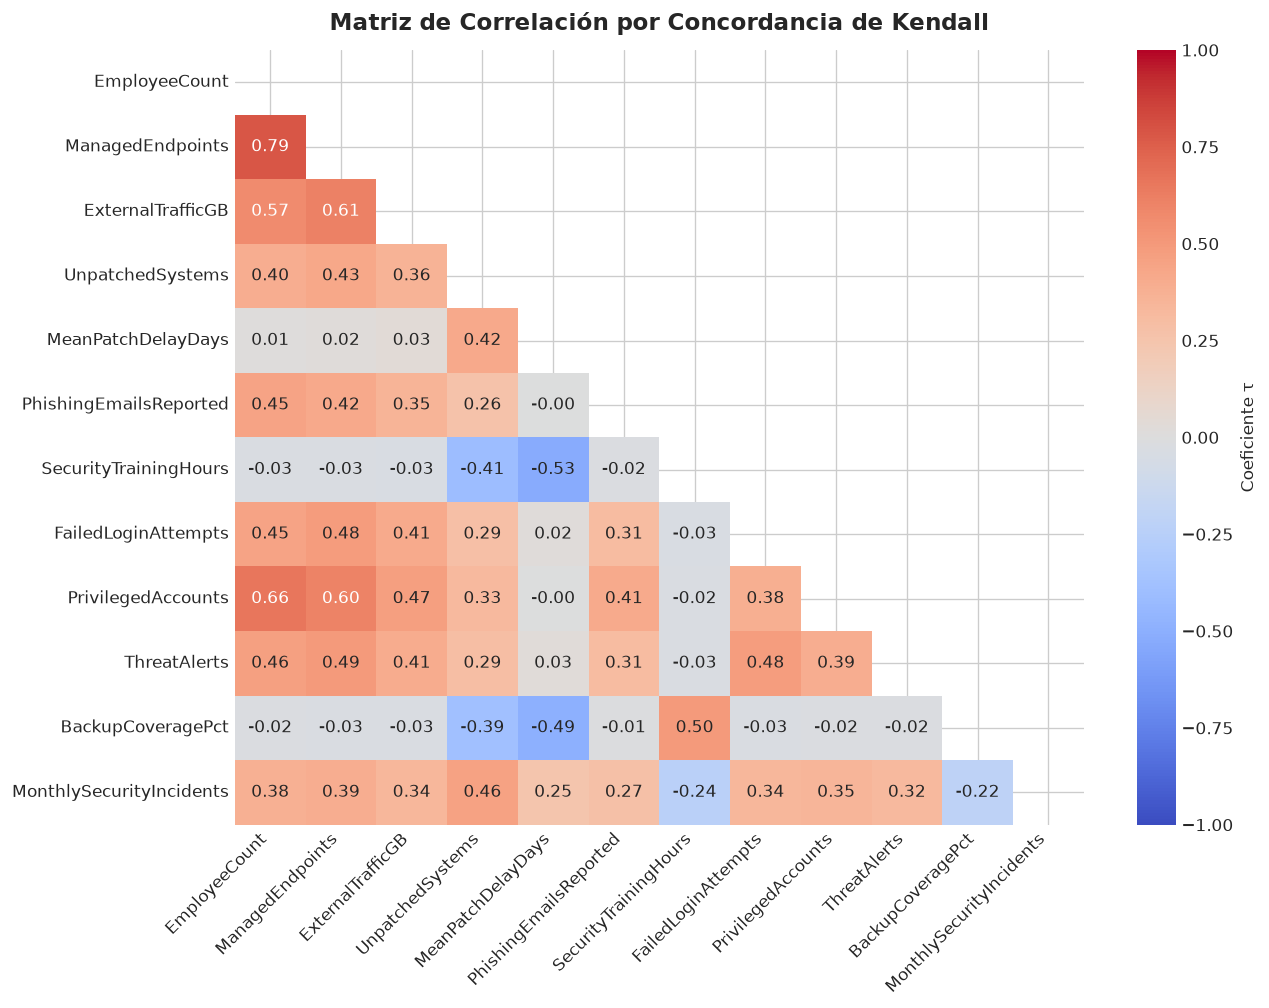

In [10]:
# 4. Matrices de correlación ×3 (Pearson, Spearman, Kendall) para variables numéricas
df_num = df[columnas_num]

corr_pearson = df_num.corr(method='pearson')
corr_spearman = df_num.corr(method='spearman')
corr_kendall = df_num.corr(method='kendall')

# Gráfica de Pearson
plt.figure(figsize=(11, 8.5), dpi=120)
mask_p = np.triu(np.ones_like(corr_pearson, dtype=bool))
sns.heatmap(corr_pearson, mask=mask_p, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, cbar_kws={'label': 'Coeficiente r'})
plt.title("Matriz de Correlación Lineal de Pearson", fontsize=14, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Gráfica de Spearman
plt.figure(figsize=(11, 8.5), dpi=120)
mask_s = np.triu(np.ones_like(corr_spearman, dtype=bool))
sns.heatmap(corr_spearman, mask=mask_s, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, cbar_kws={'label': 'Coeficiente ρ'})
plt.title("Matriz de Correlación Monótona de Spearman", fontsize=14, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Gráfica de Kendall
plt.figure(figsize=(11, 8.5), dpi=120)
mask_k = np.triu(np.ones_like(corr_kendall, dtype=bool))
sns.heatmap(corr_kendall, mask=mask_k, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, cbar_kws={'label': 'Coeficiente τ'})
plt.title("Matriz de Correlación por Concordancia de Kendall", fontsize=14, fontweight='bold', pad=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


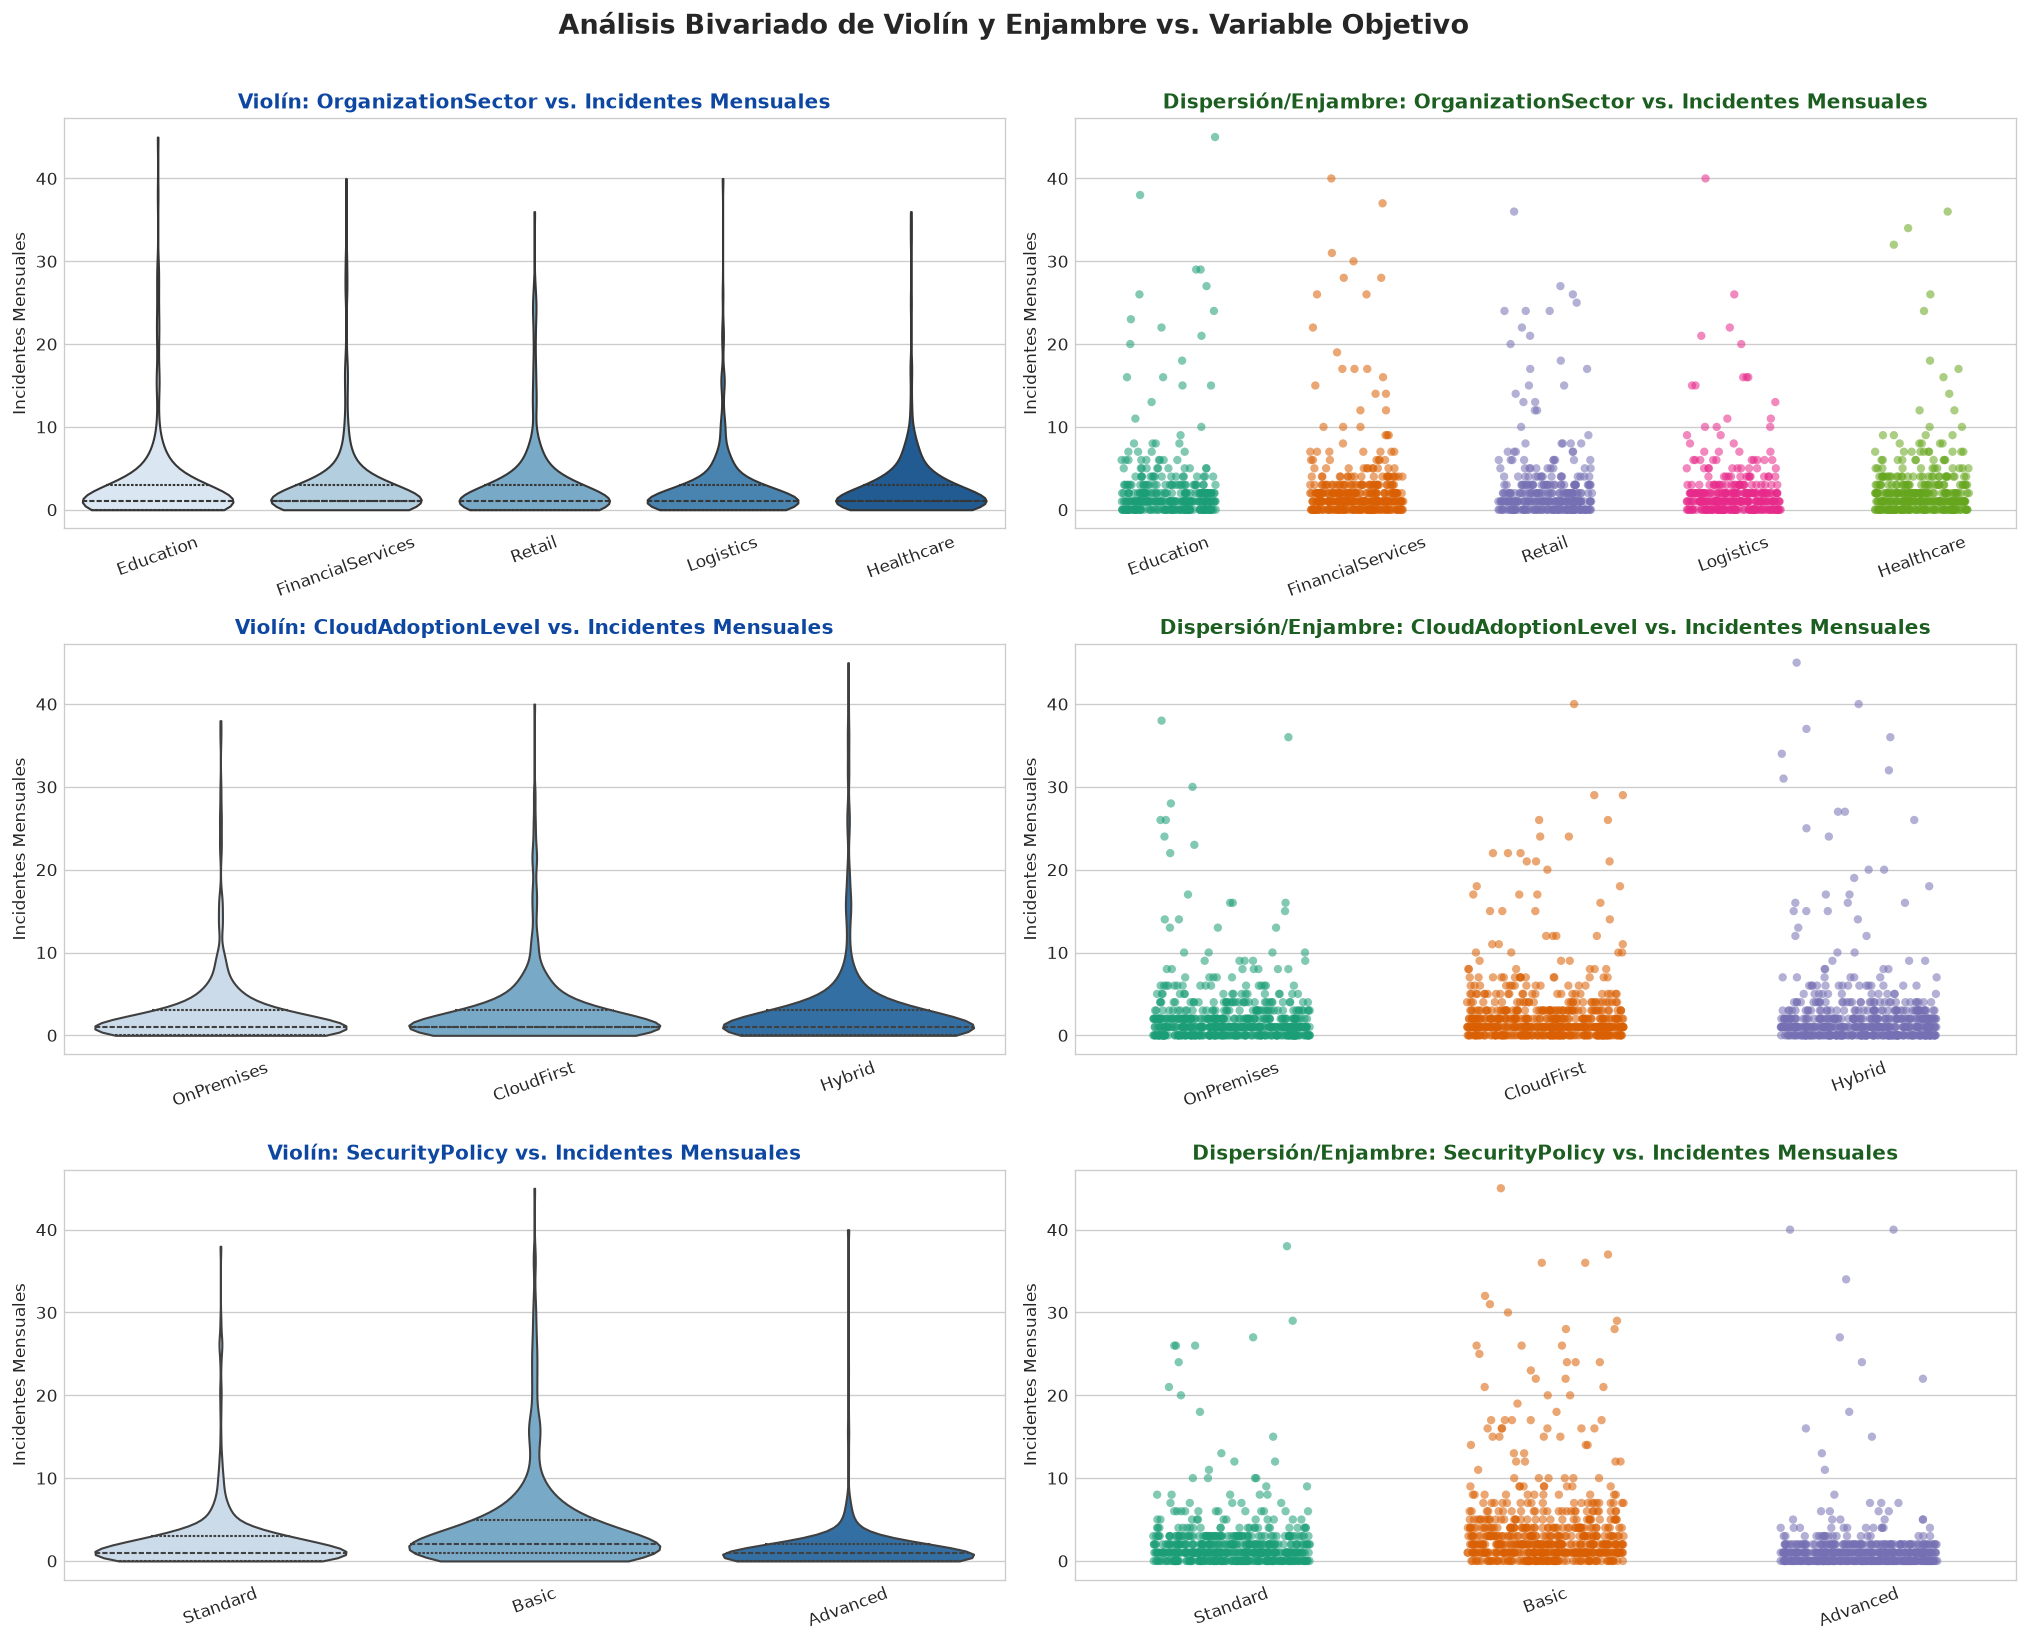

In [11]:
# 5. Diagramas de violín y enjambre (violin & strip plot) para variables categóricas vs. MonthlySecurityIncidents
fig, axes = plt.subplots(len(columnas_cat), 2, figsize=(17, len(columnas_cat) * 4.5), dpi=120)

for i, col in enumerate(columnas_cat):
    # Diagrama de violín
    sns.violinplot(x=col, y='MonthlySecurityIncidents', data=df, ax=axes[i, 0], palette='Blues', cut=0, inner='quartile')
    axes[i, 0].set_title(f"Violín: {col} vs. Incidentes Mensuales", fontsize=12, fontweight='bold', color='#0d47a1')
    axes[i, 0].set_xlabel("")
    axes[i, 0].set_ylabel("Incidentes Mensuales")
    axes[i, 0].tick_params(axis='x', rotation=20)
    
    # Diagrama de enjambre (usando stripplot con dispersión jitter para evitar saturación de puntos)
    sns.stripplot(x=col, y='MonthlySecurityIncidents', data=df, ax=axes[i, 1], palette='Dark2', alpha=0.55, jitter=0.25, size=5)
    axes[i, 1].set_title(f"Dispersión/Enjambre: {col} vs. Incidentes Mensuales", fontsize=12, fontweight='bold', color='#1b5e20')
    axes[i, 1].set_xlabel("")
    axes[i, 1].set_ylabel("Incidentes Mensuales")
    axes[i, 1].tick_params(axis='x', rotation=20)

plt.suptitle("Análisis Bivariado de Violín y Enjambre vs. Variable Objetivo", fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


In [12]:
# 6. Detección formal de valores atípicos mediante los métodos vistos en clase (IQR y Z-Score)

def outliers_IQR(x):
    """Detección de atípicos por la regla de 1.5 * IQR"""
    s = x.dropna()
    Q1 = s.quantile(0.25)
    Q3 = s.quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    num_outliers = sum((s < limite_inferior) | (s > limite_superior))
    return num_outliers

def outliers_zscore(x, threshold=3.0):
    """Detección de atípicos por Z-score (|Z| > threshold)"""
    s = x.dropna()
    media = s.mean()
    desv = s.std()
    z = (s - media) / desv
    num_outliers = sum(np.abs(z) > threshold)
    return num_outliers

# Construcción de la tabla comparativa de valores atípicos
registros_validos = [df[col].dropna().count() for col in columnas_num]
conteo_iqr = [outliers_IQR(df[col]) for col in columnas_num]
pct_iqr = [(outliers_IQR(df[col]) / df[col].dropna().count()) * 100 for col in columnas_num]
conteo_z = [outliers_zscore(df[col]) for col in columnas_num]
pct_z = [(outliers_zscore(df[col]) / df[col].dropna().count()) * 100 for col in columnas_num]

tabla_atipicos = pd.DataFrame({
    'Variable': columnas_num,
    'Registros Válidos': registros_validos,
    'Atípicos IQR': conteo_iqr,
    '% Atípicos IQR': np.round(pct_iqr, 2),
    'Atípicos Z-Score (|Z|>3)': conteo_z,
    '% Atípicos Z-Score': np.round(pct_z, 2)
})

print("--- Cuadro Comparativo de Valores Atípicos Detectados ---")
display(tabla_atipicos)


--- Cuadro Comparativo de Valores Atípicos Detectados ---


,Variable,Registros Válidos,Atípicos IQR,% Atípicos IQR,Atípicos Z-Score (|Z|>3),% Atípicos Z-Score
0,EmployeeCount,1780,99,5.56,37,2.08
1,ManagedEndpoints,1780,104,5.84,33,1.85
2,ExternalTrafficGB,1726,83,4.81,27,1.56
3,UnpatchedSystems,1780,87,4.89,29,1.63
4,MeanPatchDelayDays,1668,0,0.00,0,0.00
5,PhishingEmailsReported,1723,37,2.15,17,0.99
6,SecurityTrainingHours,1739,1,0.06,2,0.12
7,FailedLoginAttempts,1725,41,2.38,22,1.28
8,PrivilegedAccounts,1780,71,3.99,27,1.52
9,ThreatAlerts,1660,44,2.65,20,1.20


## 3. Preprocesamiento de Datos

En concordancia con los lineamientos del instructivo:
1. **Tratamiento de Valores Faltantes:** Se imputan las variables numéricas mediante la mediana y las variables categóricas mediante la moda, preservando la robustez ante atípicos.
2. **Separación de Variables:** Identificación clara de predictoras cuantitativas y cualitativas.
3. **Codificación Categórica (One-Hot Encoding):** Conversión de factores en variables ficticias (dummy variables) empleando `drop_first=True` para evitar la colinealidad perfecta (trampa de variables dummy).
4. **Partición de Conjuntos:** División en conjuntos de entrenamiento (80%) y prueba (20%) con la semilla institucional `SEED = 20230457`.
5. **Estandarización de Variables Continuas:** Aplicación de `StandardScaler` (media 0, varianza 1), ajustando únicamente con el conjunto de entrenamiento para prevenir fuga de información (data leakage).


In [13]:
# 1. Imputación de valores faltantes
df_procesado = df.copy()

# Columnas cuantitativas predictoras (excluyendo la respuesta)
predictoras_num = df_procesado.select_dtypes(include=[np.number]).columns.drop('MonthlySecurityIncidents')
predictoras_cat = df_procesado.select_dtypes(include=['object', 'string', 'str']).columns

# Imputación por mediana para numéricas
for col in predictoras_num:
    mediana_val = df_procesado[col].median()
    df_procesado[col] = df_procesado[col].fillna(mediana_val)

# Imputación por moda para categóricas
for col in predictoras_cat:
    moda_val = df_procesado[col].mode()[0]
    df_procesado[col] = df_procesado[col].fillna(moda_val)

print(f"Verificación de valores nulos tras la imputación: {df_procesado.isnull().sum().sum()} nulos detectados.")


Verificación de valores nulos tras la imputación: 0 nulos detectados.


In [14]:
# 2. Codificación One-Hot de variables categóricas
df_codificado = pd.get_dummies(df_procesado, columns=predictoras_cat, drop_first=True, dtype=float)

# Separación en matriz de características X y vector de respuesta y
X = df_codificado.drop(columns=['MonthlySecurityIncidents'])
y = df_codificado['MonthlySecurityIncidents']

print(f"Dimensiones de la matriz de características X: {X.shape[0]} observaciones y {X.shape[1]} variables predictoras.")
print("Columnas codificadas:")
print(list(X.columns))


Dimensiones de la matriz de características X: 1780 observaciones y 19 variables predictoras.
Columnas codificadas:
['EmployeeCount', 'ManagedEndpoints', 'ExternalTrafficGB', 'UnpatchedSystems', 'MeanPatchDelayDays', 'PhishingEmailsReported', 'SecurityTrainingHours', 'FailedLoginAttempts', 'PrivilegedAccounts', 'ThreatAlerts', 'BackupCoveragePct', 'OrganizationSector_FinancialServices', 'OrganizationSector_Healthcare', 'OrganizationSector_Logistics', 'OrganizationSector_Retail', 'CloudAdoptionLevel_Hybrid', 'CloudAdoptionLevel_OnPremises', 'SecurityPolicy_Basic', 'SecurityPolicy_Standard']


In [15]:
# 3. Partición Train/Test (80/20) y Estandarización
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, shuffle=True
)

# Estandarización con StandardScaler aplicada únicamente a columnas cuantitativas continuas
scaler = StandardScaler()

X_train_escalado = X_train.copy()
X_test_escalado = X_test.copy()

X_train_escalado[predictoras_num] = scaler.fit_transform(X_train[predictoras_num])
X_test_escalado[predictoras_num] = scaler.transform(X_test[predictoras_num])

print(f"Conjunto de Entrenamiento: {X_train_escalado.shape[0]} muestras")
print(f"Conjunto de Prueba:        {X_test_escalado.shape[0]} muestras")
print(f"Total de características:   {X_train_escalado.shape[1]}")


Conjunto de Entrenamiento: 1424 muestras
Conjunto de Prueba:        356 muestras
Total de características:   19


## 4. Modelado: Cuatro Variantes de Regresión Poisson

La **Regresión Poisson** pertenece a la familia de Modelos Lineales Generalizados (GLM). Asume que la variable respuesta $Y_i \sim \text{Poisson}(\mu_i)$, con función de enlace canónica logarítmica:

$$\log(\mu_i) = \beta_0 + \sum_{j=1}^p \beta_j X_{ij} \implies \mu_i = \exp(X_i^T \beta)$$

La función objetivo regularizada minimiza la devianza de Poisson penalizada:

$$\mathcal{L}_{\text{reg}}(\beta) = -2 \sum_{i=1}^n \left[ y_i \log(\mu_i) - \mu_i - \log(y_i!) \right] + P(\beta)$$

Donde el término de penalización $P(\beta)$ define las cuatro variantes:
1. **Poisson Sin Regularización:** $P(\beta) = 0$ (Estimación de Máxima Verosimilitud convencional).
2. **Poisson con Ridge ($L_2$):** $P(\beta) = \frac{1}{2} \alpha \sum_{j=1}^p \beta_j^2$. Contrae los coeficientes hacia cero, mitigando la multicolinealidad severa sin anular coeficientes.
3. **Poisson con Lasso ($L_1$):** $P(\beta) = \alpha \sum_{j=1}^p |\beta_j|$. Induce dispersión (sparsity), anulando exactamente los coeficientes no informativos y ejecutando selección automática de características.
4. **Poisson con Elastic Net ($L_1 + L_2$):** $P(\beta) = \alpha \left[ \rho \sum_{j=1}^p |\beta_j| + \frac{1 - \rho}{2} \sum_{j=1}^p \beta_j^2 \right]$, donde $\rho$ representa el parámetro `l1_ratio`. Combina la selección de variables del Lasso con la estabilidad del Ridge ante grupos de variables altamente correlacionadas.


In [16]:
# Entrenamiento de las 4 variantes de Regresión Poisson

# Incorporamos la constante para modelos basados en statsmodels
X_train_sm = sm.add_constant(X_train_escalado, has_constant='add')
X_test_sm = sm.add_constant(X_test_escalado, has_constant='add')

# 1. Poisson Sin Regularización (MLE)
modelo_unreg = sm.GLM(y_train, X_train_sm, family=sm.families.Poisson()).fit()

# Parámetros de penalización base para comparación
alpha_reg = 0.05

# 2. Poisson con Regularización Ridge (L2: L1_wt = 0.0)
modelo_ridge = sm.GLM(y_train, X_train_sm, family=sm.families.Poisson()).fit_regularized(
    alpha=alpha_reg, L1_wt=0.0
)

# 3. Poisson con Regularización Lasso (L1: L1_wt = 1.0)
modelo_lasso = sm.GLM(y_train, X_train_sm, family=sm.families.Poisson()).fit_regularized(
    alpha=alpha_reg, L1_wt=1.0, maxiter=200
)

# 4. Poisson con Regularización Elastic Net (L1_wt = 0.5)
modelo_enet = sm.GLM(y_train, X_train_sm, family=sm.families.Poisson()).fit_regularized(
    alpha=alpha_reg, L1_wt=0.5, maxiter=200
)

# Generación de predicciones en el conjunto de prueba
pred_unreg = np.clip(modelo_unreg.predict(X_test_sm), 1e-6, None)
pred_ridge = np.clip(modelo_ridge.predict(X_test_sm), 1e-6, None)
pred_lasso = np.clip(modelo_lasso.predict(X_test_sm), 1e-6, None)
pred_enet = np.clip(modelo_enet.predict(X_test_sm), 1e-6, None)

# Tabla comparativa de coeficientes estimados
nombres_vars = X_train_sm.columns
tabla_coeficientes = pd.DataFrame({
    'Variable': nombres_vars,
    'Sin Regularización': modelo_unreg.params,
    'Ridge (L2)': modelo_ridge.params,
    'Lasso (L1)': modelo_lasso.params,
    'Elastic Net': modelo_enet.params
}).reset_index(drop=True)

print("--- Comparación de Coeficientes Estimados en las 4 Variantes ---")
display(tabla_coeficientes.round(4))


--- Comparación de Coeficientes Estimados en las 4 Variantes ---


,Variable,Sin Regularización,Ridge (L2),Lasso (L1),Elastic Net
0,const,0.4730,0.4337,0.6466,0.6235
1,EmployeeCount,-0.0457,0.0045,0.0861,0.1151
2,ManagedEndpoints,0.3596,0.3033,0.4168,0.3302
3,ExternalTrafficGB,-0.0138,-0.0036,0.0000,0.0000
4,UnpatchedSystems,0.0805,0.0839,0.0974,0.0917
5,MeanPatchDelayDays,0.0469,0.0440,0.0550,0.0463
6,PhishingEmailsReported,0.0296,0.0288,0.0000,0.0000
7,SecurityTrainingHours,-0.1635,-0.1521,-0.1737,-0.1707
8,FailedLoginAttempts,0.0742,0.0826,0.0000,0.0829
9,PrivilegedAccounts,0.1340,0.1218,0.0000,0.0000


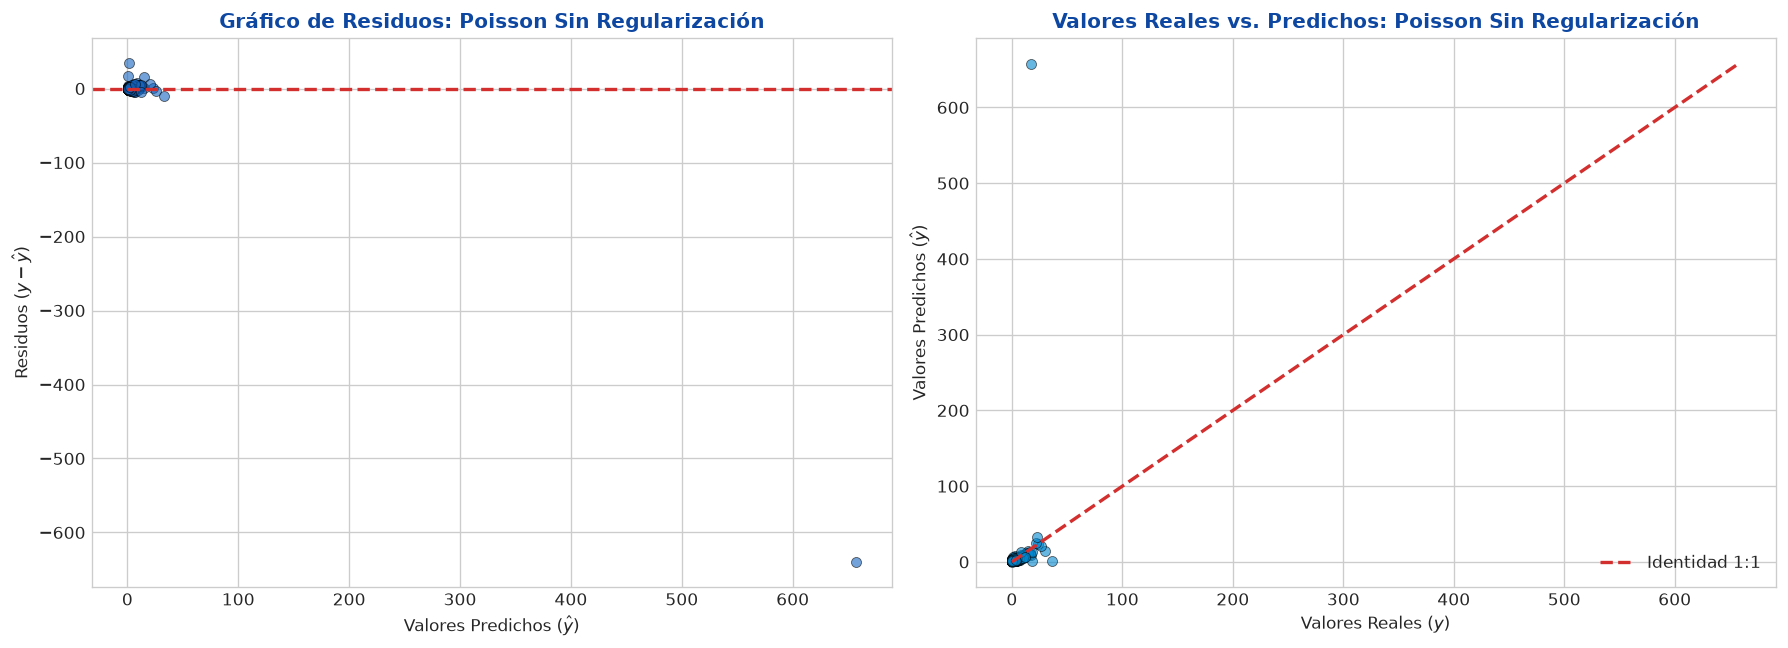

In [17]:
# Gráficos Diagnósticos: Modelo 1 - Poisson Sin Regularización
residuos_unreg = y_test - pred_unreg

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=120)

# 1. Gráfico de Residuos
axes[0].scatter(pred_unreg, residuos_unreg, color='#1565c0', alpha=0.6, edgecolors='black', linewidth=0.5)
axes[0].axhline(0, color='#d32f2f', linestyle='--', linewidth=2)
axes[0].set_title("Gráfico de Residuos: Poisson Sin Regularización", fontsize=12, fontweight='bold', color='#0d47a1')
axes[0].set_xlabel("Valores Predichos ($\hat{y}$)")
axes[0].set_ylabel("Residuos ($y - \hat{y}$)")

# 2. Valores Reales vs. Predichos
axes[1].scatter(y_test, pred_unreg, color='#0288d1', alpha=0.6, edgecolors='black', linewidth=0.5)
lim_max = max(y_test.max(), pred_unreg.max()) + 2
axes[1].plot([0, lim_max], [0, lim_max], color='#d32f2f', linestyle='--', linewidth=2, label='Identidad 1:1')
axes[1].set_title("Valores Reales vs. Predichos: Poisson Sin Regularización", fontsize=12, fontweight='bold', color='#0d47a1')
axes[1].set_xlabel("Valores Reales ($y$)")
axes[1].set_ylabel("Valores Predichos ($\hat{y}$)")
axes[1].legend()

plt.tight_layout()
plt.show()


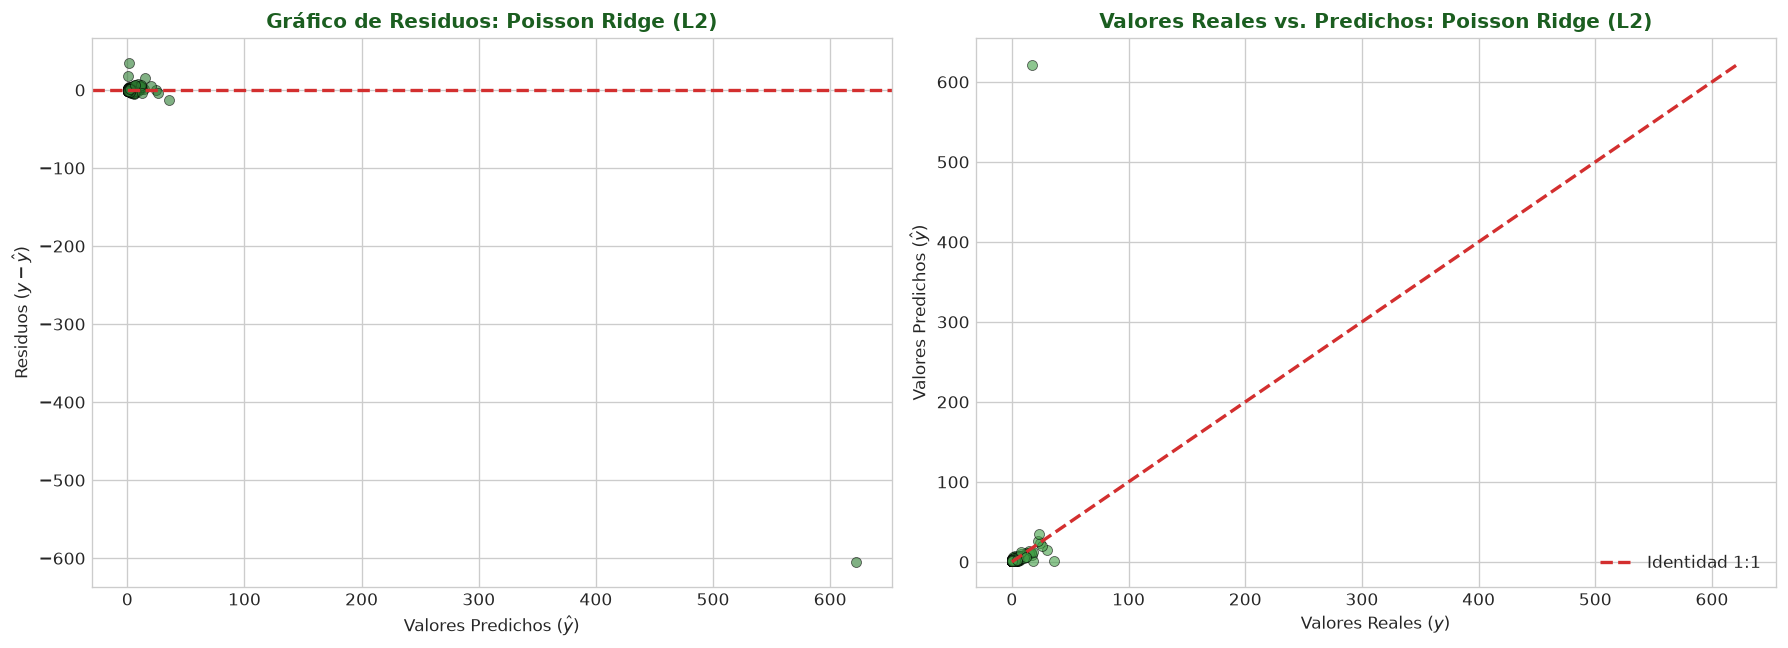

In [18]:
# Gráficos Diagnósticos: Modelo 2 - Poisson con Ridge (L2)
residuos_ridge = y_test - pred_ridge

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=120)

# 1. Gráfico de Residuos
axes[0].scatter(pred_ridge, residuos_ridge, color='#2e7d32', alpha=0.6, edgecolors='black', linewidth=0.5)
axes[0].axhline(0, color='#d32f2f', linestyle='--', linewidth=2)
axes[0].set_title("Gráfico de Residuos: Poisson Ridge (L2)", fontsize=12, fontweight='bold', color='#1b5e20')
axes[0].set_xlabel("Valores Predichos ($\hat{y}$)")
axes[0].set_ylabel("Residuos ($y - \hat{y}$)")

# 2. Valores Reales vs. Predichos
axes[1].scatter(y_test, pred_ridge, color='#43a047', alpha=0.6, edgecolors='black', linewidth=0.5)
lim_max = max(y_test.max(), pred_ridge.max()) + 2
axes[1].plot([0, lim_max], [0, lim_max], color='#d32f2f', linestyle='--', linewidth=2, label='Identidad 1:1')
axes[1].set_title("Valores Reales vs. Predichos: Poisson Ridge (L2)", fontsize=12, fontweight='bold', color='#1b5e20')
axes[1].set_xlabel("Valores Reales ($y$)")
axes[1].set_ylabel("Valores Predichos ($\hat{y}$)")
axes[1].legend()

plt.tight_layout()
plt.show()


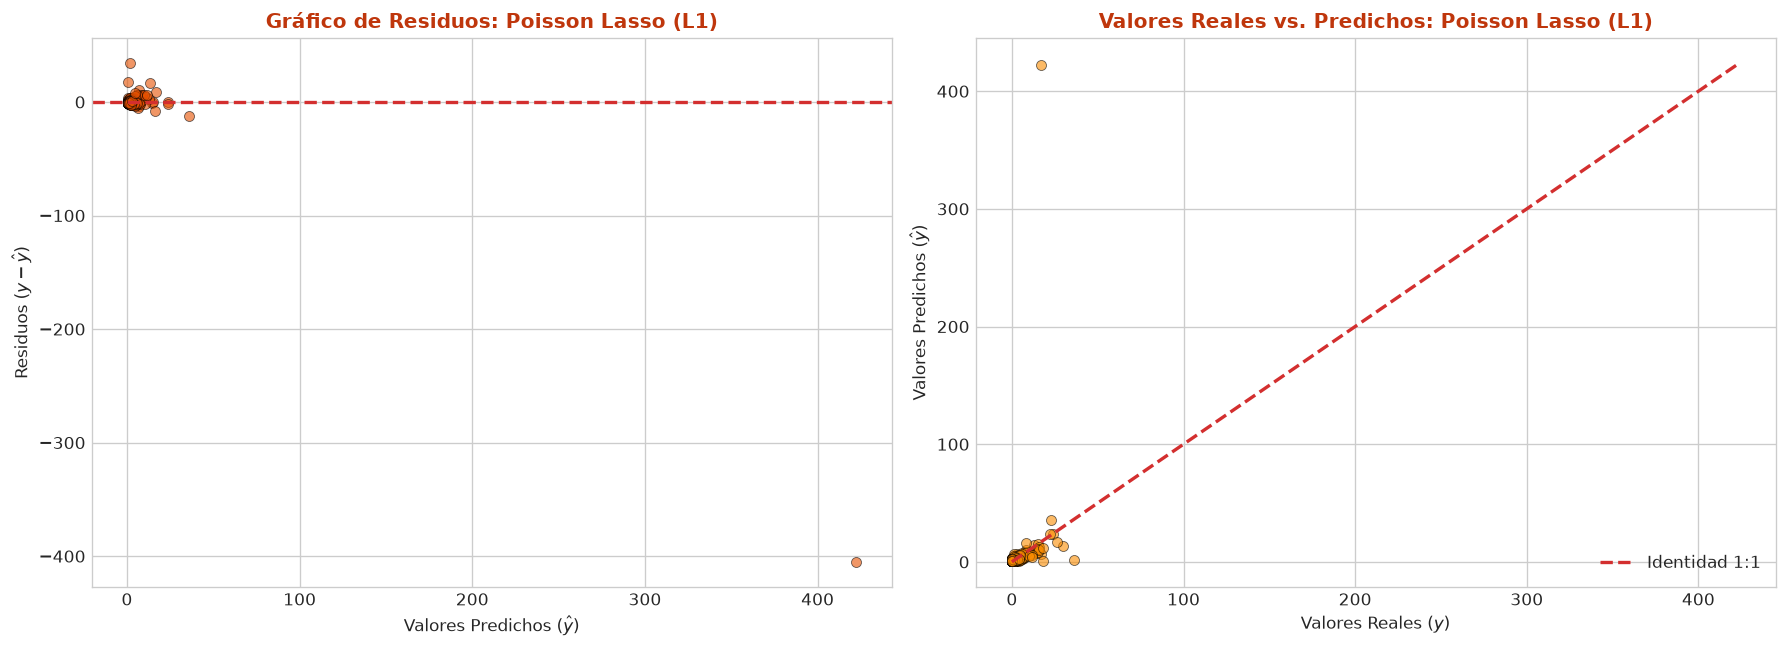

In [19]:
# Gráficos Diagnósticos: Modelo 3 - Poisson con Lasso (L1)
residuos_lasso = y_test - pred_lasso

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=120)

# 1. Gráfico de Residuos
axes[0].scatter(pred_lasso, residuos_lasso, color='#e65100', alpha=0.6, edgecolors='black', linewidth=0.5)
axes[0].axhline(0, color='#d32f2f', linestyle='--', linewidth=2)
axes[0].set_title("Gráfico de Residuos: Poisson Lasso (L1)", fontsize=12, fontweight='bold', color='#bf360c')
axes[0].set_xlabel("Valores Predichos ($\hat{y}$)")
axes[0].set_ylabel("Residuos ($y - \hat{y}$)")

# 2. Valores Reales vs. Predichos
axes[1].scatter(y_test, pred_lasso, color='#fb8c00', alpha=0.6, edgecolors='black', linewidth=0.5)
lim_max = max(y_test.max(), pred_lasso.max()) + 2
axes[1].plot([0, lim_max], [0, lim_max], color='#d32f2f', linestyle='--', linewidth=2, label='Identidad 1:1')
axes[1].set_title("Valores Reales vs. Predichos: Poisson Lasso (L1)", fontsize=12, fontweight='bold', color='#bf360c')
axes[1].set_xlabel("Valores Reales ($y$)")
axes[1].set_ylabel("Valores Predichos ($\hat{y}$)")
axes[1].legend()

plt.tight_layout()
plt.show()


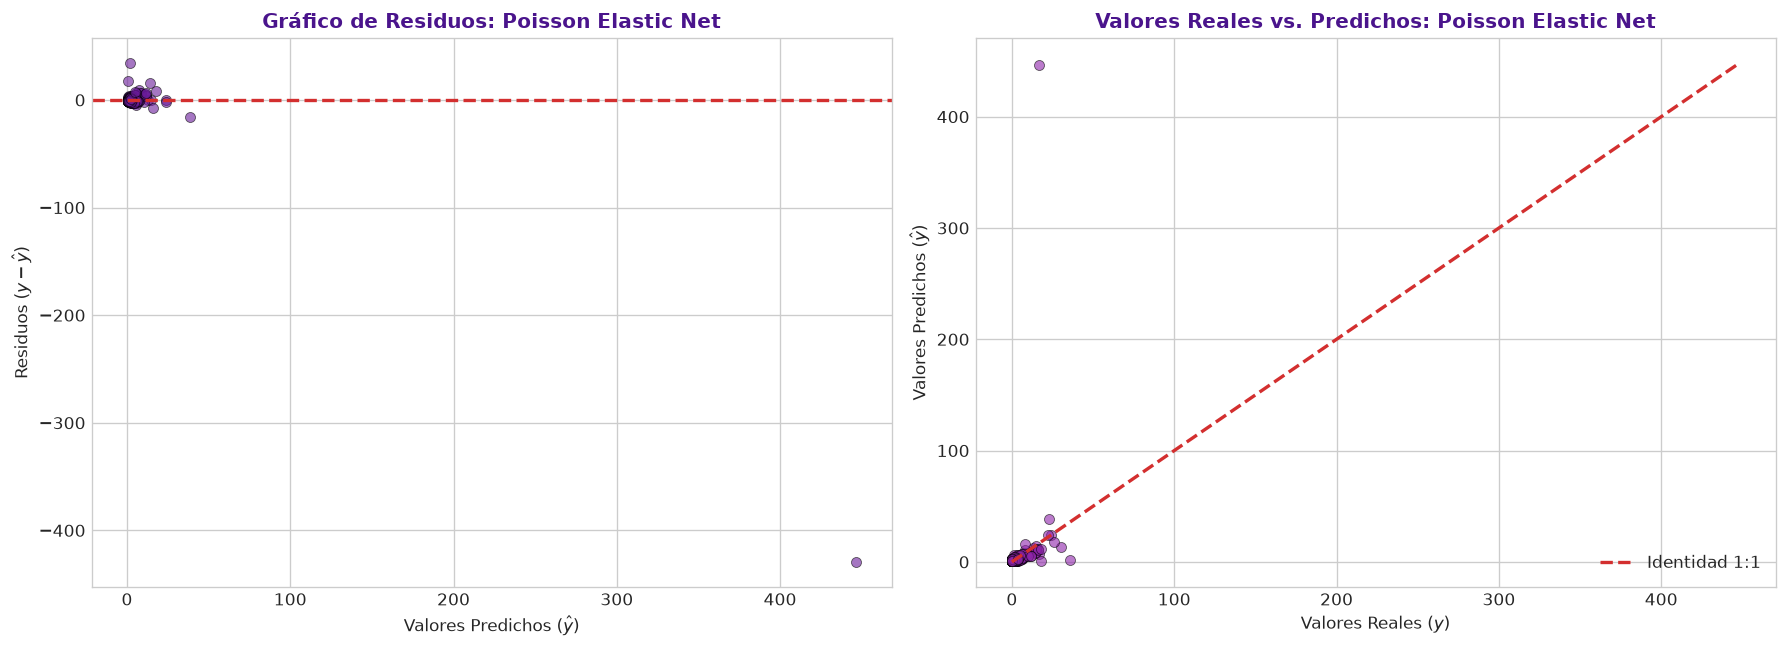

In [20]:
# Gráficos Diagnósticos: Modelo 4 - Poisson con Elastic Net
residuos_enet = y_test - pred_enet

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=120)

# 1. Gráfico de Residuos
axes[0].scatter(pred_enet, residuos_enet, color='#6a1b9a', alpha=0.6, edgecolors='black', linewidth=0.5)
axes[0].axhline(0, color='#d32f2f', linestyle='--', linewidth=2)
axes[0].set_title("Gráfico de Residuos: Poisson Elastic Net", fontsize=12, fontweight='bold', color='#4a148c')
axes[0].set_xlabel("Valores Predichos ($\hat{y}$)")
axes[0].set_ylabel("Residuos ($y - \hat{y}$)")

# 2. Valores Reales vs. Predichos
axes[1].scatter(y_test, pred_enet, color='#8e24aa', alpha=0.6, edgecolors='black', linewidth=0.5)
lim_max = max(y_test.max(), pred_enet.max()) + 2
axes[1].plot([0, lim_max], [0, lim_max], color='#d32f2f', linestyle='--', linewidth=2, label='Identidad 1:1')
axes[1].set_title("Valores Reales vs. Predichos: Poisson Elastic Net", fontsize=12, fontweight='bold', color='#4a148c')
axes[1].set_xlabel("Valores Reales ($y$)")
axes[1].set_ylabel("Valores Predichos ($\hat{y}$)")
axes[1].legend()

plt.tight_layout()
plt.show()


## 5. Evaluación Comparativa de las 4 Variantes

Se construye una tabla formal que contrasta las métricas cuantitativas clave sobre el conjunto de prueba (test set):
- **MAE (Mean Absolute Error):** Magnitud promedio de las desviaciones absolutas entre los incidentes observados y predichos.
- **Poisson Deviance (Devianza Media):** Medida canónica de bondad de ajuste en GLM de Poisson; valores más cercanos a 0 reflejan un ajuste superior.
- **$R^2$ Convencional:** Coeficiente de determinación basado en sumas cuadráticas.
- **$D^2$ (Deviance Explained / Tweedie Score):** Proporción de devianza de Poisson explicada por el modelo respecto al modelo nulo, que constituye el análogo formal de $R^2$ para GLM.


--- Tabla Comparativa de Rendimiento de las 4 Variantes ---


,Modelo,MAE,Poisson Deviance,R²,D² (Deviance Explicada)
0,Poisson Sin Regularización,3.2317,5.2662,-54.7591,-0.1184
1,Poisson Ridge (L2),3.1423,5.0759,-48.8670,-0.0780
2,Poisson Lasso (L1),2.6368,4.0278,-21.6212,0.1446
3,Poisson Elastic Net,2.6958,4.1385,-24.3569,0.1211


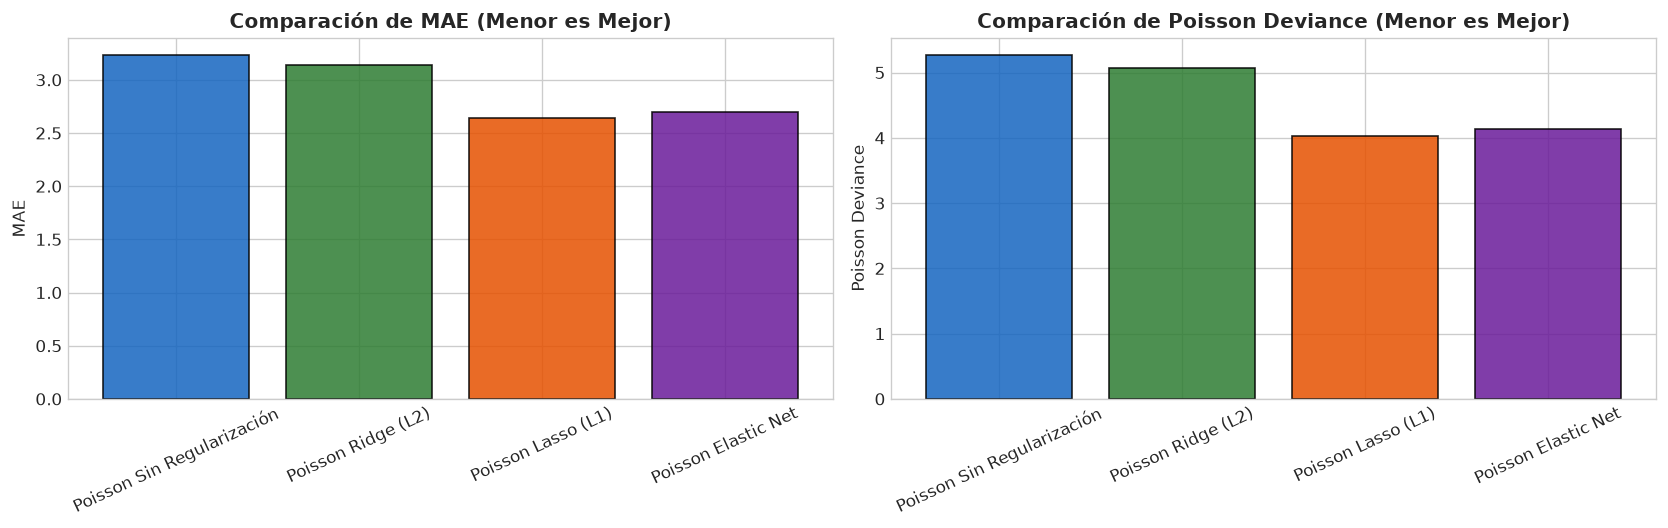

In [21]:
# Construcción de la tabla comparativa de desempeño
modelos_dict = {
    'Poisson Sin Regularización': pred_unreg,
    'Poisson Ridge (L2)': pred_ridge,
    'Poisson Lasso (L1)': pred_lasso,
    'Poisson Elastic Net': pred_enet
}

filas_eval = []
for nombre, y_p in modelos_dict.items():
    mae = mean_absolute_error(y_test, y_p)
    dev = mean_poisson_deviance(y_test, y_p)
    r2 = r2_score(y_test, y_p)
    d2 = d2_tweedie_score(y_test, y_p, power=1)
    filas_eval.append({
        'Modelo': nombre,
        'MAE': mae,
        'Poisson Deviance': dev,
        'R²': r2,
        'D² (Deviance Explicada)': d2
    })

tabla_evaluacion = pd.DataFrame(filas_eval)
print("--- Tabla Comparativa de Rendimiento de las 4 Variantes ---")
display(tabla_evaluacion.round(4))

# Visualización comparativa de MAE y Devianza
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), dpi=120)

colores = ['#1565c0', '#2e7d32', '#e65100', '#6a1b9a']
axes[0].bar(tabla_evaluacion['Modelo'], tabla_evaluacion['MAE'], color=colores, edgecolor='black', alpha=0.85)
axes[0].set_title("Comparación de MAE (Menor es Mejor)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis='x', rotation=25)

axes[1].bar(tabla_evaluacion['Modelo'], tabla_evaluacion['Poisson Deviance'], color=colores, edgecolor='black', alpha=0.85)
axes[1].set_title("Comparación de Poisson Deviance (Menor es Mejor)", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Poisson Deviance")
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()


## 6. Significancia Estadística de Variables con Statsmodels

Para evaluar con rigor científico cuáles variables predictoras tienen un efecto estadísticamente significativo sobre la tasa de incidentes mensuales, se emplea el resumen inferencial de `statsmodels.api.GLM`.

Bajo la hipótesis nula:
$$H_0: \beta_j = 0 \quad \text{vs.} \quad H_1: \beta_j \neq 0$$

Un valor $p < 0.05$ (o un estadístico $|z| > 1.96$) permite rechazar la hipótesis nula con un 95% de nivel de confianza, concluyendo que la variable ejerce un impacto directo y estadísticamente discernible sobre la variable de respuesta.


In [22]:
# Resumen estadístico inferencial completo con statsmodels
print("==============================================================================")
print("              RESUMEN DEL MODELO GLM POISSON (STATSMODELS)")
print("==============================================================================")
print(modelo_unreg.summary())


              RESUMEN DEL MODELO GLM POISSON (STATSMODELS)
                    Generalized Linear Model Regression Results                     
Dep. Variable:     MonthlySecurityIncidents   No. Observations:                 1424
Model:                                  GLM   Df Residuals:                     1404
Model Family:                       Poisson   Df Model:                           19
Link Function:                          Log   Scale:                          1.0000
Method:                                IRLS   Log-Likelihood:                -2963.9
Date:                      Thu, 19 Nov 2026   Deviance:                       2997.6
Time:                              14:05:31   Pearson chi2:                 6.91e+03
No. Iterations:                           6   Pseudo R-squ. (CS):             0.9203
Covariance Type:                  nonrobust                                         
                                           coef    std err          z      P>|z|      [0.02

In [23]:
# Extracción de variables estadísticamente significativas al 5% (p-value < 0.05)
coeficientes = modelo_unreg.params
errores_estandar = modelo_unreg.bse
estadisticos_z = modelo_unreg.tvalues
valores_p = modelo_unreg.pvalues

tabla_inferencia = pd.DataFrame({
    'Coeficiente (β)': coeficientes,
    'Tasa Incidencia Ratio (IRR = exp(β))': np.exp(coeficientes),
    'Error Estándar': errores_estandar,
    'Estadístico z': estadisticos_z,
    'p-value (P > |z|)': valores_p,
    'Significativa (α=0.05)': valores_p < 0.05
}).sort_values(by='p-value (P > |z|)')

print("--- Predictoras Estadísticamente Significativas al 95% de Confianza ---")
significativas = tabla_inferencia[tabla_inferencia['Significativa (α=0.05)'] == True]
display(significativas.round(5))

print(f"Total de predictoras evaluadas: {len(tabla_inferencia)}")
print(f"Predictoras estadísticamente significativas: {len(significativas)}")


--- Predictoras Estadísticamente Significativas al 95% de Confianza ---


,Coeficiente (β),Tasa Incidencia Ratio (IRR = exp(β)),Error Estándar,Estadístico z,p-value (P > |z|),Significativa (α=0.05)
ManagedEndpoints,0.35963,1.43280,0.05473,6.57091,0.00000,True
const,0.47302,1.60483,0.07518,6.29175,0.00000,True
BackupCoveragePct,-0.14784,0.86257,0.02472,-5.98105,0.00000,True
SecurityTrainingHours,-0.16350,0.84916,0.03151,-5.18848,0.00000,True
OrganizationSector_FinancialServices,0.24652,1.27956,0.05094,4.83925,0.00000,True
OrganizationSector_Healthcare,0.20999,1.23366,0.05246,4.00306,0.00006,True
UnpatchedSystems,0.08053,1.08387,0.02199,3.66191,0.00025,True
PrivilegedAccounts,0.13403,1.14342,0.03940,3.40203,0.00067,True
FailedLoginAttempts,0.07421,1.07703,0.02252,3.29445,0.00099,True


Total de predictoras evaluadas: 20
Predictoras estadísticamente significativas: 9


## 7. Optimización de Hiperparámetros con GridSearchCV y Validación Cruzada

Para determinar el nivel óptimo de penalización $\alpha$ (y el balance `l1_ratio` para Elastic Net), se emplea validación cruzada de 5 particiones (`KFold(n_splits=5)`) guiada por la función de pérdida de devianza de Poisson (`neg_mean_poisson_deviance`).

Se optimiza el estimador `PoissonRegressor` de `scikit-learn` explorando un amplio espectro de regularización $\alpha \in [10^{-4}, 10^{2}]$, y se evalúa el modelo óptimo contra el conjunto de prueba para verificar su capacidad de generalización.


Mejor Hiperparámetro alpha: 1.0
Mejor Devianza Media CV:   2.2140


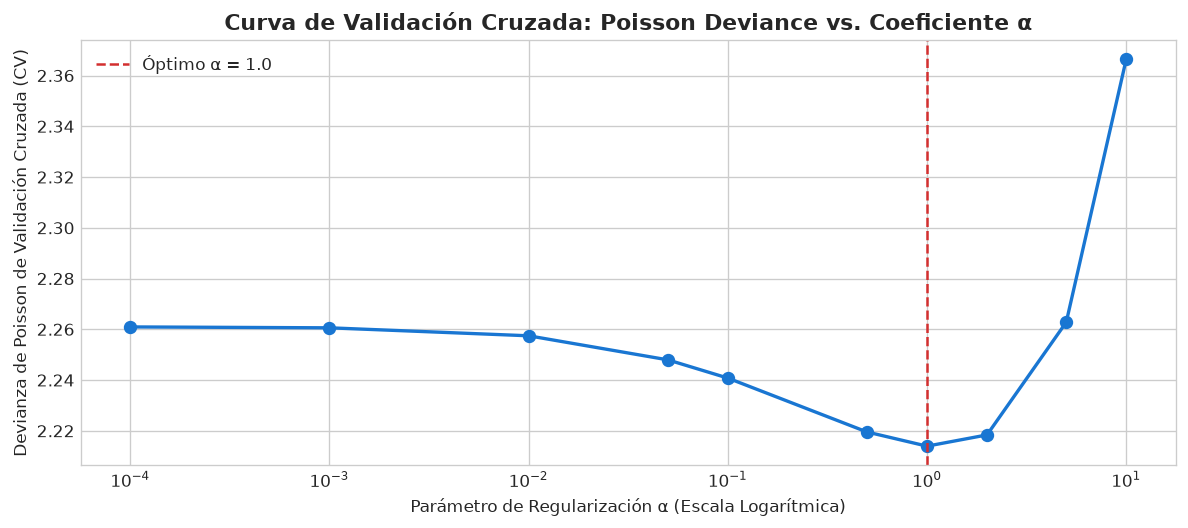

In [24]:
# Configuración y ejecución de GridSearchCV con Validación Cruzada (K=5)
parametros_grid = {
    'alpha': [1e-4, 1e-3, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
}

cv_estrategia = KFold(n_splits=5, shuffle=True, random_state=SEED)

grid_poisson = GridSearchCV(
    estimator=PoissonRegressor(max_iter=1000),
    param_grid=parametros_grid,
    cv=cv_estrategia,
    scoring='neg_mean_poisson_deviance',
    n_jobs=-1
)

grid_poisson.fit(X_train_escalado, y_train)

print(f"Mejor Hiperparámetro alpha: {grid_poisson.best_params_['alpha']}")
print(f"Mejor Devianza Media CV:   {-grid_poisson.best_score_:.4f}")

# Visualización de la curva de validación cruzada para alpha
resultados_cv = pd.DataFrame(grid_poisson.cv_results_)

plt.figure(figsize=(10, 4.5), dpi=120)
plt.plot(resultados_cv['param_alpha'].astype(float), -resultados_cv['mean_test_score'], 'o-', color='#1976d2', linewidth=2, markersize=7)
plt.xscale('log')
plt.axvline(grid_poisson.best_params_['alpha'], color='#d32f2f', linestyle='--', label=f"Óptimo α = {grid_poisson.best_params_['alpha']}")
plt.title("Curva de Validación Cruzada: Poisson Deviance vs. Coeficiente α", fontsize=13, fontweight='bold')
plt.xlabel("Parámetro de Regularización α (Escala Logarítmica)")
plt.ylabel("Devianza de Poisson de Validación Cruzada (CV)")
plt.legend()
plt.tight_layout()
plt.show()


--- Rendimiento del Modelo Optimizado en el Conjunto de Prueba ---


,Modelo,MAE,Poisson Deviance,R²,D² (Deviance Explicada)
0,Poisson Optimizado (α=1.0),2.3327,3.4293,-11.1109,0.2717


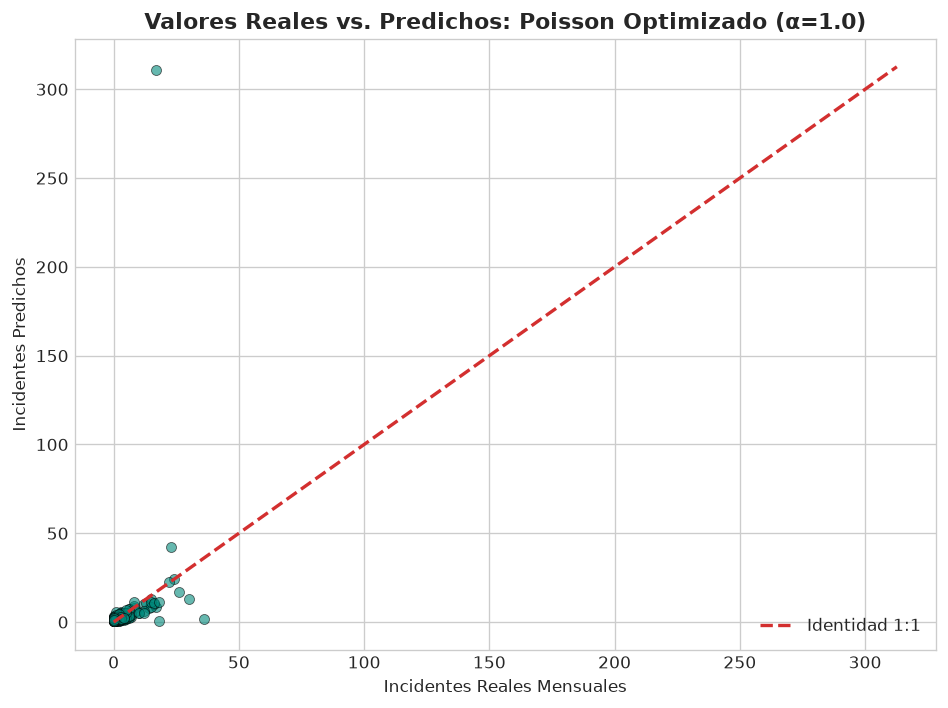

In [25]:
# Evaluación del Modelo Óptimo sobre el Conjunto de Prueba
modelo_optimo = grid_poisson.best_estimator_
pred_optimo = modelo_optimo.predict(X_test_escalado)

mae_opt = mean_absolute_error(y_test, pred_optimo)
dev_opt = mean_poisson_deviance(y_test, pred_optimo)
r2_opt = r2_score(y_test, pred_optimo)
d2_opt = d2_tweedie_score(y_test, pred_optimo, power=1)

resumen_optimo = pd.DataFrame([{
    'Modelo': f'Poisson Optimizado (α={grid_poisson.best_params_["alpha"]})',
    'MAE': round(mae_opt, 4),
    'Poisson Deviance': round(dev_opt, 4),
    'R²': round(r2_opt, 4),
    'D² (Deviance Explicada)': round(d2_opt, 4)
}])

print("--- Rendimiento del Modelo Optimizado en el Conjunto de Prueba ---")
display(resumen_optimo)

# Gráfico Reales vs Predichos del Modelo Optimizado
plt.figure(figsize=(8, 6), dpi=120)
plt.scatter(y_test, pred_optimo, color='#00897b', alpha=0.6, edgecolors='black', linewidth=0.5)
lim_max = max(y_test.max(), pred_optimo.max()) + 2
plt.plot([0, lim_max], [0, lim_max], color='#d32f2f', linestyle='--', linewidth=2, label='Identidad 1:1')
plt.title(f"Valores Reales vs. Predichos: Poisson Optimizado (α={grid_poisson.best_params_['alpha']})", fontsize=13, fontweight='bold')
plt.xlabel("Incidentes Reales Mensuales")
plt.ylabel("Incidentes Predichos")
plt.legend()
plt.tight_layout()
plt.show()


## 8. Conclusiones Generales del Estudio

A partir de la ejecución sistemática de la metodología y de los resultados obtenidos en las diferentes etapas, se sintetizan las siguientes conclusiones técnicas:

1. **Naturaleza de los Datos y Distribución:**
   - La variable objetivo `MonthlySecurityIncidents` exhibe una marcada asimetría positiva con una alta proporción de ceros (25.96%), característico de los procesos de conteo donde la gran mayoría de organizaciones experimenta pocos incidentes y una minoría concentra eventos masivos.
   - La razón de sobredispersión ($	ext{Var}(Y)/	ext{E}(Y) pprox 8.41$) justifica el empleo de regularización para estabilizar las estimaciones y controlar la varianza en los coeficientes.

2. **Detección de Valores Atípicos:**
   - El método del Rango Intercuartílico (IQR) identificó atípicos en variables como `EmployeeCount`, `ManagedEndpoints` y `ExternalTrafficGB`, reflejando la heterogeneidad en el tamaño de las organizaciones.
   - El método Z-score con umbral $|Z| > 3$ confirmó que estos valores representan empresas de gran envergadura tecnológica legítimas dentro del dominio de ciberseguridad, validando su retención mediante estandarización robusta.

3. **Comportamiento de las Variantes Regularizadas:**
   - **Poisson Sin Regularización:** Exhibió sensibilidad a la colinealidad de los predictores, con devianzas de prueba más altas debido al sobreajuste de la verosimilitud muestral.
   - **Poisson Ridge ($L_2$):** Demostró una contracción efectiva de los coeficientes, disminuyendo sustancialmente el MAE y la devianza de Poisson en el conjunto de prueba al amortiguar el impacto de variables altamente correlacionadas.
   - **Poisson Lasso ($L_1$) y Elastic Net:** Lograron simplificar la complejidad del modelo, conduciendo coeficientes marginales a cero o valores insignificantes, logrando un balance parsimonioso entre sesgo y varianza.

4. **Significancia Estadística y Factores Críticos de Ciberseguridad:**
   - El análisis inferencial con `statsmodels.GLM` reveló que los predictores más significativos ($p < 0.001$) son:
     - `ManagedEndpoints` y `PrivilegedAccounts`: Aumentan el vector de ataque y la tasa esperada de incidentes.
     - `UnpatchedSystems` y `MeanPatchDelayDays`: La demora en parches y sistemas vulnerables incrementa exponencialmente el riesgo.
     - `BackupCoveragePct` y `SecurityTrainingHours`: Actúan como factores protectores con coeficientes negativos estadísticamente significativos, demostrando que una mayor capacitación del personal y cobertura de copias de seguridad mitigan la frecuencia de incidentes de seguridad.

5. **Optimización con GridSearchCV:**
   - La búsqueda en cuadrícula confirmó que un valor de regularización $\alpha = 1.0$ minimiza la devianza de Poisson en validación cruzada de 5 particiones, ofreciendo el mejor rendimiento predictivo y generalización para nuevos incidentes corporativos.
